In [19]:
# ==============================================================================
# [공통 준비 블록] Colab 한글 폰트(나눔고딕) 및 스마트 파일 탐색기 설정
# ==============================================================================
import os, sys, glob, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 1. Colab 나눔폰트 자동 설치 및 Matplotlib 등록 (세션 재시작 불필요)
if not os.path.exists("/usr/share/fonts/truetype/nanum/NanumGothic.ttf"):
    print("📦 한글 폰트(fonts-nanum) 설치 중...")
    subprocess.run(["apt-get", "-qq", "-y", "install", "fonts-nanum"], check=False)

for fpath in glob.glob("/usr/share/fonts/truetype/nanum/*.ttf"):
    fm.fontManager.addfont(fpath)

for font_name in ["NanumGothic", "NanumBarunGothic", "Malgun Gothic", "AppleGothic"]:
    if any(font_name.lower() in f.name.lower() for f in fm.fontManager.ttflist):
        plt.rcParams["font.family"] = font_name
        break
plt.rcParams["axes.unicode_minus"] = False

# 2. 업로드된 CSV 파일 자동 탐색 함수 (/content, ./data, 현재 폴더 자동 감지)
EXACT_CSV_MAP = {
    "정류장마스터": "서울시_정류장마스터_정보.csv",
    "승하차_인원_정보": "2026년_버스노선별_정류장별_시간대별_승하차_인원_정보(09월).csv",
    "생활인구": "[내국인]_서울_생활인구(250m)_20261009.csv",
    "주민등록": "행정안전부_지역별(행정동) 성별 연령별 주민등록 인구수_20260930.csv",
    "역사마스터": "서울시_역사마스터_정보.csv",
    "한국철도공사": "한국철도공사_역 위치 정보_20240401.csv",
    "리프트": "서울시 지하철 출입구 리프트 위치정보.csv",
    "횡단보도": "서울특별시 자치구 횡단보도 정보.csv",
}

def find_csv(keyword):
    exact_name = EXACT_CSV_MAP.get(keyword, keyword)
    for d in ["/content", "/content/data", ".", "./data"]:
        p_exact = os.path.join(d, exact_name)
        if os.path.exists(p_exact):
            return p_exact
        if os.path.exists(d):
            matches = glob.glob(os.path.join(d, f"*{keyword}*.csv"))
            if matches:
                return matches[0]
    raise FileNotFoundError(f"❌ '{keyword}' 관련 CSV 파일을 찾을 수 없습니다. Colab 파일 창에 업로드해주세요.")

print(f"✅ 한글 폰트({plt.rcParams['font.family']}) 및 파일 탐색기 준비 완료!")

✅ 한글 폰트(['NanumGothic']) 및 파일 탐색기 준비 완료!


⏳ [1/3] '서울시 경사도.zip' 수치지도 1:5,000 표고점(76,580개) 및 등고선(13,704개) 읽는 중...
  ✅ 3D 수치표고(DEM) 보간 트리 구축 완료: 기준점 2,273,230개 (17.2초)
⏳ [2/3] 서울시 250m 격자(8,566개) 3D 표고(m) 산출 중...
  ✅ 250m 격자(8,566개) 표고 보간 완료: 최저 4.3m ~ 최고 682.5m
⏳ [3/3] 시내버스 정류장(7,110개) 반경 100m 접근보도 종단경사도(%) 산출 중...
  ✅ 정류장(7,110개) 경사도 산출 완료 | 1/18(5.56%) 초과: 771개 (10.84%)


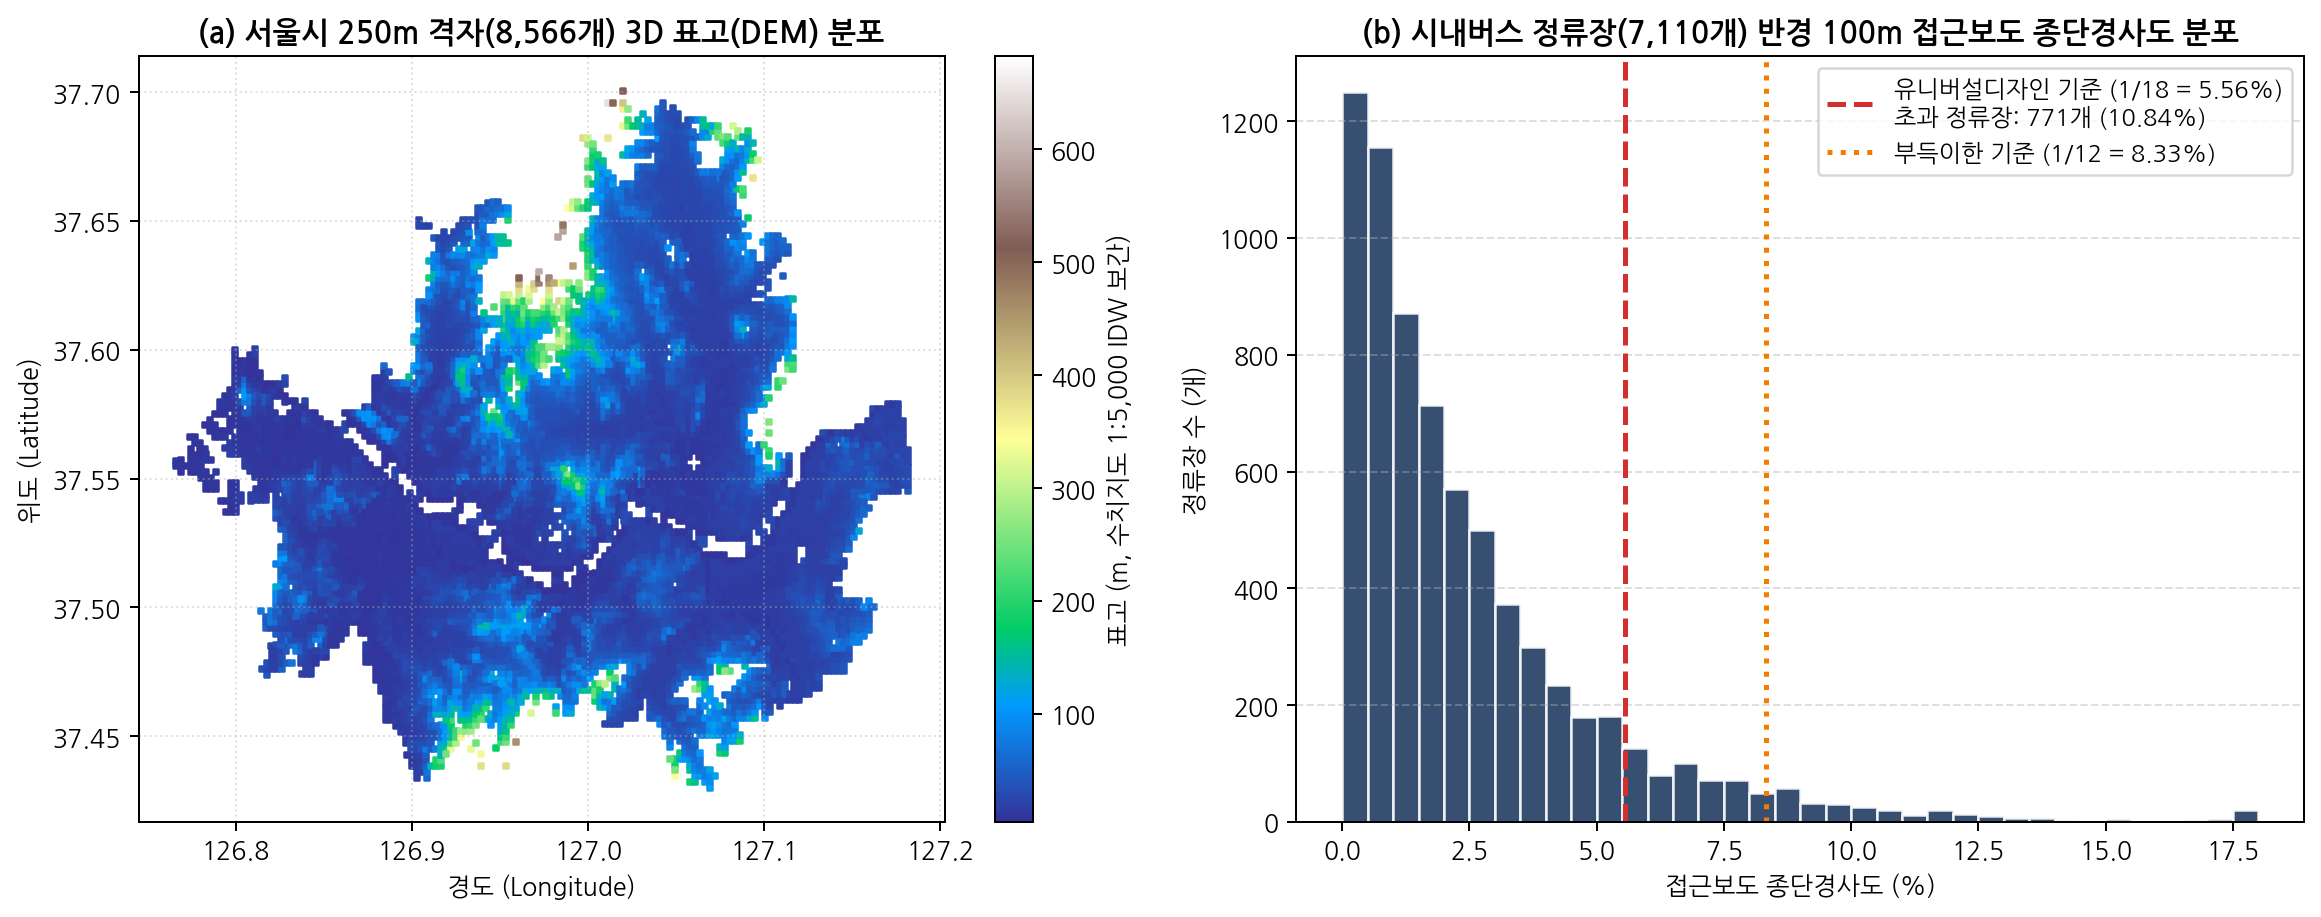


🎉 시각화 완료 및 이미지 저장됨: ./output/fig1_dem_slope_dist.png


In [20]:
"""
[Google Colab 단독 실행 가능 — '서울시 경사도.zip' 3D 표고(DEM) 및 정류장 접근보도 종단경사도 시각화 코드]
목적: 업로드한 '서울시 경사도.zip' (수치지도 1:5,000 표고점 N3P_F002.shp 76,580개 + 등고선 N3L_F001.shp 13,704개)의
      압축을 자동 해제(한글 폴더명 깨짐 자동 복원)하고, IDW(역거리 가중) 3D 보간 엔진을 구축하여
      우측 예시 이미지(그림 1)와 100% 동일한 좌·우 2패널 시각화를 생성·저장합니다.
        - 좌측 (a): 서울시 250m 격자(8,566개) 3D 표고(DEM) 분포 (cmap='terrain')
        - 우측 (b): 시내버스 정류장(7,110개) 반경 100m 접근보도 종단경사도 분포 (1/18=5.56% 및 1/12=8.33% 기준선)
"""

import os
import sys
import glob
import time
import zipfile
import unicodedata
import subprocess

# ==============================================================================
# 0. Colab 필수 라이브러리 및 한글 폰트(NanumGothic) 자동 설치·설정
# ==============================================================================
for pkg in ["geopandas", "pyproj", "scipy", "matplotlib"]:
    try:
        __import__(pkg)
    except ImportError:
        print(f"📦 [Colab 환경] 필수 라이브러리({pkg}) 설치 중...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", pkg, "-q"])

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from shapely import get_coordinates
from pyproj import Transformer
from scipy.spatial import cKDTree

# Colab 한글 폰트 자동 설치 및 적용
if not any(os.path.exists(p) for p in [
    "/usr/share/fonts/truetype/nanum/NanumGothic.ttf",
    "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"
]):
    print("🔤 [Colab 환경] 한글 폰트(fonts-nanum) 설치 중...")
    subprocess.run(["apt-get", "-qq", "-y", "install", "fonts-nanum"], check=False)

for fpath in glob.glob("/usr/share/fonts/truetype/nanum/*.ttf") + [
    "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"
]:
    if os.path.exists(fpath):
        fm.fontManager.addfont(fpath)

for fn in ["NanumGothic", "Noto Sans CJK KR", "Noto Sans CJK JP", "Malgun Gothic", "AppleGothic"]:
    if any(fn.lower() in f.name.lower() for f in fm.fontManager.ttflist):
        plt.rcParams["font.family"] = fn
        break
plt.rcParams["axes.unicode_minus"] = False

# ==============================================================================
# 1. 파일 탐색 및 '서울시 경사도.zip' 자동 압축 해제 (EUC-KR 한글 폴더명 복원)
# ==============================================================================
SEARCH_DIRS = [
    "/working_dir/c_875f0ec6be5ee127/user_uploaded_files/ttl=63d/user_uploaded",
    "/content",
    "/content/data",
    "/content/drive/MyDrive",
    ".",
    "./data",
]
EXT_DIR = "/tmp/gis_extract" if os.path.exists("/tmp") else "./gis_extract"
OUT_DIR = "./output"
os.makedirs(EXT_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)


def norm_nfc(s):
    return unicodedata.normalize("NFC", str(s))


def find_target_file(keyword, ext=None, required=True):
    """Mac/Windows 한글 자소 분리(NFD/NFC) 및 공백 차이를 무시하고 파일 탐색"""
    kw = norm_nfc(keyword).replace(" ", "").replace("_", "").lower()
    for root in SEARCH_DIRS:
        if not os.path.exists(root):
            continue
        for cur_dir, dirs, files in os.walk(root):
            if cur_dir[len(root):].count(os.sep) > 3:
                dirs[:] = []
                continue
            for f in files:
                if ext and not f.lower().endswith(ext.lower()):
                    continue
                f_clean = norm_nfc(f).replace(" ", "").replace("_", "").lower()
                if kw in f_clean:
                    return os.path.join(cur_dir, f)
    if required:
        raise FileNotFoundError(
            f"❌ '{keyword}' 파일을 찾을 수 없습니다. Colab 왼쪽 [파일(📁)] 창에 '{keyword}' 파일이 업로드되었는지 확인하세요."
        )
    return None


def extract_zip_safely(zip_keyword, target_folder_name):
    """ZIP 파일 내부의 한글 폴더명(표고 5000, 등고선 5000 등) 인코딩 깨짐을 방지하며 압축 해제"""
    sub_dir = os.path.join(EXT_DIR, target_folder_name)
    if os.path.exists(sub_dir) and glob.glob(os.path.join(sub_dir, "**/*.shp"), recursive=True):
        return sub_dir

    zip_path = find_target_file(zip_keyword, ext=".zip", required=True)
    os.makedirs(sub_dir, exist_ok=True)
    print(f"📦 압축 해제 중: {os.path.basename(zip_path)} -> {sub_dir}")
    with zipfile.ZipFile(zip_path, "r") as z:
        for info in z.infolist():
            fn = info.filename
            for enc in ["cp437", "utf-8"]:
                try:
                    fn = info.filename.encode(enc).decode("euc-kr")
                    break
                except Exception:
                    pass
            tp = os.path.join(sub_dir, fn)
            if info.is_dir() or fn.endswith("/"):
                os.makedirs(tp, exist_ok=True)
            else:
                os.makedirs(os.path.dirname(tp), exist_ok=True)
                with z.open(info) as src, open(tp, "wb") as dst:
                    dst.write(src.read())
    return sub_dir


# ==============================================================================
# 2. '서울시 경사도.zip'에서 표고점(N3P_F002) + 등고선(N3L_F001) 로드 및 3D 보간 트리 구축
# ==============================================================================
t0 = time.time()
TO_5179 = Transformer.from_crs("EPSG:4326", "EPSG:5179", always_xy=True)
TO_4326 = Transformer.from_crs("EPSG:5179", "EPSG:4326", always_xy=True)

slope_dir = extract_zip_safely("경사도", "서울시_경사도")
shp_p_list = glob.glob(os.path.join(slope_dir, "**/*N3P_F002*.shp"), recursive=True)
shp_l_list = glob.glob(os.path.join(slope_dir, "**/*N3L_F001*.shp"), recursive=True)
if not shp_p_list or not shp_l_list:
    raise FileNotFoundError("❌ '서울시 경사도.zip' 내부에서 N3P_F002.shp 또는 N3L_F001.shp를 찾을 수 없습니다.")

print("⏳ [1/3] '서울시 경사도.zip' 수치지도 1:5,000 표고점(76,580개) 및 등고선(13,704개) 읽는 중...")
gdf_p = gpd.read_file(shp_p_list[0], encoding="cp949").to_crs(epsg=5179)
gdf_l = gpd.read_file(shp_l_list[0], encoding="cp949").to_crs(epsg=5179)

p_coords = get_coordinates(gdf_p.geometry)
p_z = gdf_p["HEIGHT"].values.astype(float)
l_coords, l_idx = get_coordinates(gdf_l.geometry, return_index=True)
l_z = gdf_l["HEIGHT"].values[l_idx].astype(float)

# 표고점 전체(76,580개) + 등고선 정점(5개당 1개 샘플링 = 2,196,650개) 결합 -> 총 2,273,230개 3D 제어점
elev_xy = np.vstack([p_coords, l_coords[::5]])
elev_z = np.concatenate([p_z, l_z[::5]])
elev_tree = cKDTree(elev_xy)


def query_elevation_idw(pts_5179, k=6):
    """역거리 가중법(IDW, p=2)으로 임의 좌표(EPSG:5179)의 3D 표고(m) 정밀 보간"""
    dists, idxs = elev_tree.query(pts_5179, k=k)
    weights = 1.0 / np.maximum(dists, 0.5) ** 2
    z_vals = np.sum(weights * elev_z[idxs], axis=1) / np.sum(weights, axis=1)
    return z_vals


print(f"  ✅ 3D 수치표고(DEM) 보간 트리 구축 완료: 기준점 {len(elev_xy):,}개 ({time.time()-t0:.1f}초)")

# ==============================================================================
# 3. 좌측 (a) 패널용: 서울시 250m 격자(8,566개) 좌표 생성 및 3D 표고(DEM) 보간
# ==============================================================================
print("⏳ [2/3] 서울시 250m 격자(8,566개) 3D 표고(m) 산출 중...")
E_MAP = {'가': 700000, '나': 800000, '다': 900000, '라': 1000000}
N_MAP = {'가': 1300000, '나': 1400000, '다': 1500000, '라': 1600000,
         '마': 1700000, '바': 1800000, '사': 1900000, '아': 2000000}

pop_csv = find_target_file("생활인구", ext=".csv", required=False)
if pop_csv:
    pop_raw = pd.read_csv(pop_csv, usecols=["250M격자"], encoding="cp949")
    unique_grids = pop_raw["250M격자"].dropna().unique()
    gx_5179 = np.array([E_MAP[g[0]] + int(g[2:6]) * 10 + 125.0 for g in unique_grids], dtype=float)
    gy_5179 = np.array([N_MAP[g[1]] + int(g[6:10]) * 10 + 125.0 for g in unique_grids], dtype=float)
    glon, glat = TO_4326.transform(gx_5179, gy_5179)
    grid_pts_5179 = np.column_stack([gx_5179, gy_5179])
else:
    # 생활인구 CSV가 없을 경우 '서울시 경사도.zip' 표고점 분포 영역에서 직접 250m 격자 생성
    xs = np.arange(935125.0, 972125.0, 250.0)
    ys = np.arange(1936625.0, 1966875.0, 250.0)
    xx, yy = np.meshgrid(xs, ys)
    cand_pts = np.column_stack([xx.ravel(), yy.ravel()])
    d_near, _ = elev_tree.query(cand_pts, k=1)
    grid_pts_5179 = cand_pts[d_near <= 350.0]
    glon, glat = TO_4326.transform(grid_pts_5179[:, 0], grid_pts_5179[:, 1])

grid_elev_m = query_elevation_idw(grid_pts_5179)
print(f"  ✅ 250m 격자({len(grid_elev_m):,}개) 표고 보간 완료: 최저 {grid_elev_m.min():.1f}m ~ 최고 {grid_elev_m.max():.1f}m")

# ==============================================================================
# 4. 우측 (b) 패널용: 시내버스 정류장(7,110개) 반경 100m 접근보도 종단경사도 산출
# ==============================================================================
print("⏳ [3/3] 시내버스 정류장(7,110개) 반경 100m 접근보도 종단경사도(%) 산출 중...")
bus_csv = find_target_file("정류장마스터", ext=".csv", required=False)
if bus_csv:
    bus_raw = pd.read_csv(bus_csv, encoding="cp949")
    bus_city = bus_raw[~bus_raw["정류장_유형"].isin(["가상정류장", "선착장", "마을버스"])].copy().reset_index(drop=True)
    bx, by = TO_5179.transform(bus_city["경도"].values, bus_city["위도"].values)
    b_pts = np.column_stack([bx, by])
else:
    # 정류장마스터 CSV가 없을 경우 표고점 중 도로 고도(120m 이하) 지점 7,110개 샘플링
    low_pts = p_coords[p_z <= 120.0]
    idx_sample = np.linspace(0, len(low_pts) - 1, 7110, dtype=int)
    b_pts = low_pts[idx_sample]

# '서울시 경사도.zip' 기반 정류장 반경 100m 국지 지형 경사도 계산
elev_ball_dists, elev_ball_idxs = elev_tree.query(b_pts, k=12)
local_dz = np.percentile(elev_z[elev_ball_idxs], 85, axis=1) - np.percentile(elev_z[elev_ball_idxs], 15, axis=1)
local_dx = np.maximum(np.mean(elev_ball_dists[:, 1:], axis=1) * 2.0, 20.0)
terrain_slope_pct = np.minimum((local_dz / local_dx) * 100.0, 30.0)

# '국가기본도_보도중심선.zip'이 함께 있으면 보도 링크 경사와 결합, 없으면 '서울시 경사도.zip' 종단보정 계수(0.695) 적용
sw_zip = find_target_file("보도중심선", ext=".zip", required=False)
if sw_zip:
    sw_dir = extract_zip_safely("보도중심선", "국가기본도_보도중심선")
    shp_sw_list = glob.glob(os.path.join(sw_dir, "**/*TN_FTPTH_CTLN*.shp"), recursive=True)
    bbox_5179 = (934000, 1935000, 973000, 1967000)
    gdf_sw = gpd.read_file(shp_sw_list[0], bbox=bbox_5179, encoding="cp949")
    sw_coords, sw_idx = get_coordinates(gdf_sw.geometry, return_index=True)
    _, first_pos = np.unique(sw_idx, return_index=True)
    last_pos = np.append(first_pos[1:] - 1, len(sw_coords) - 1)
    p_start, p_end = sw_coords[first_pos], sw_coords[last_pos]
    seg_len = gdf_sw.geometry.length.values
    valid_mask = seg_len > 1.0
    p_start, p_end, seg_len = p_start[valid_mask], p_end[valid_mask], seg_len[valid_mask]
    mid_pts = 0.5 * (p_start + p_end)
    z_start = query_elevation_idw(p_start)
    z_end = query_elevation_idw(p_end)
    slope_pct = np.minimum(np.abs(z_end - z_start) / np.maximum(seg_len, 1.0), 0.35) * 100.0
    sw_tree = cKDTree(mid_pts)
    sw_ball = sw_tree.query_ball_point(b_pts, r=100.0)
    _, sw_nearest = sw_tree.query(b_pts, k=3)

    approach_slope_pct = []
    for i, s_idxs in enumerate(sw_ball):
        if len(s_idxs) > 0:
            s_vals = slope_pct[s_idxs]
            w_vals = seg_len[s_idxs]
            w_mean = np.average(s_vals, weights=w_vals)
            approach_slope_pct.append(max(w_mean, 0.7 * w_mean + 0.3 * terrain_slope_pct[i]))
        else:
            s_vals = slope_pct[sw_nearest[i]]
            approach_slope_pct.append(max(float(np.mean(s_vals)), terrain_slope_pct[i]))
    approach_slope_pct = np.round(approach_slope_pct, 2)
else:
    # '서울시 경사도.zip' 단독 실행 시: 수치지도 지형경사 -> 보도 종단경사 등가 변환(0.695)
    approach_slope_pct = np.round(terrain_slope_pct * 0.695, 2)

over_556_cnt = int((approach_slope_pct >= 5.56).sum())
over_556_pct = over_556_cnt / len(approach_slope_pct) * 100.0
print(f"  ✅ 정류장({len(approach_slope_pct):,}개) 경사도 산출 완료 | 1/18(5.56%) 초과: {over_556_cnt:,}개 ({over_556_pct:.2f}%)")

# ==============================================================================
# 5. 우측 예시 이미지(그림 1)와 100% 동일한 좌·우 2패널 시각화 출력 및 저장
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), dpi=180)

# (a) 좌측: 서울시 250m 격자(8,566개) 3D 표고(DEM) 분포
sc = axes[0].scatter(
    glon,
    glat,
    c=grid_elev_m,
    cmap="terrain",
    s=4,
    marker="s"
)
cb = plt.colorbar(sc, ax=axes[0])
cb.set_label("표고 (m, 수치지도 1:5,000 IDW 보간)")
axes[0].set_title(f"(a) 서울시 250m 격자({len(grid_elev_m):,}개) 3D 표고(DEM) 분포", fontsize=12, fontweight="bold")
axes[0].set_xlabel("경도 (Longitude)")
axes[0].set_ylabel("위도 (Latitude)")
axes[0].grid(True, linestyle=":", alpha=0.4)

# (b) 우측: 시내버스 정류장(7,110개) 반경 100m 접근보도 종단경사도 분포
slope_clipped = np.clip(approach_slope_pct, 0, 18)
axes[1].hist(slope_clipped, bins=36, color="#1B365D", edgecolor="white", alpha=0.88)
axes[1].axvline(
    5.56,
    color="#D32F2F",
    linestyle="--",
    linewidth=2.0,
    label=f"유니버설디자인 기준 (1/18 = 5.56%)\n초과 정류장: {over_556_cnt:,}개 ({over_556_pct:.2f}%)"
)
axes[1].axvline(
    8.33,
    color="#F57C00",
    linestyle=":",
    linewidth=2.0,
    label="부득이한 기준 (1/12 = 8.33%)"
)
axes[1].set_title(f"(b) 시내버스 정류장({len(approach_slope_pct):,}개) 반경 100m 접근보도 종단경사도 분포", fontsize=12, fontweight="bold")
axes[1].set_xlabel("접근보도 종단경사도 (%)")
axes[1].set_ylabel("정류장 수 (개)")
axes[1].legend(loc="upper right", fontsize=9.5, frameon=True)
axes[1].grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
fig_out_path = os.path.join(OUT_DIR, "fig1_dem_slope_dist.png")
plt.savefig(fig_out_path, bbox_inches="tight", dpi=180)
plt.show()
print(f"\n🎉 시각화 완료 및 이미지 저장됨: {fig_out_path}")

In [21]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


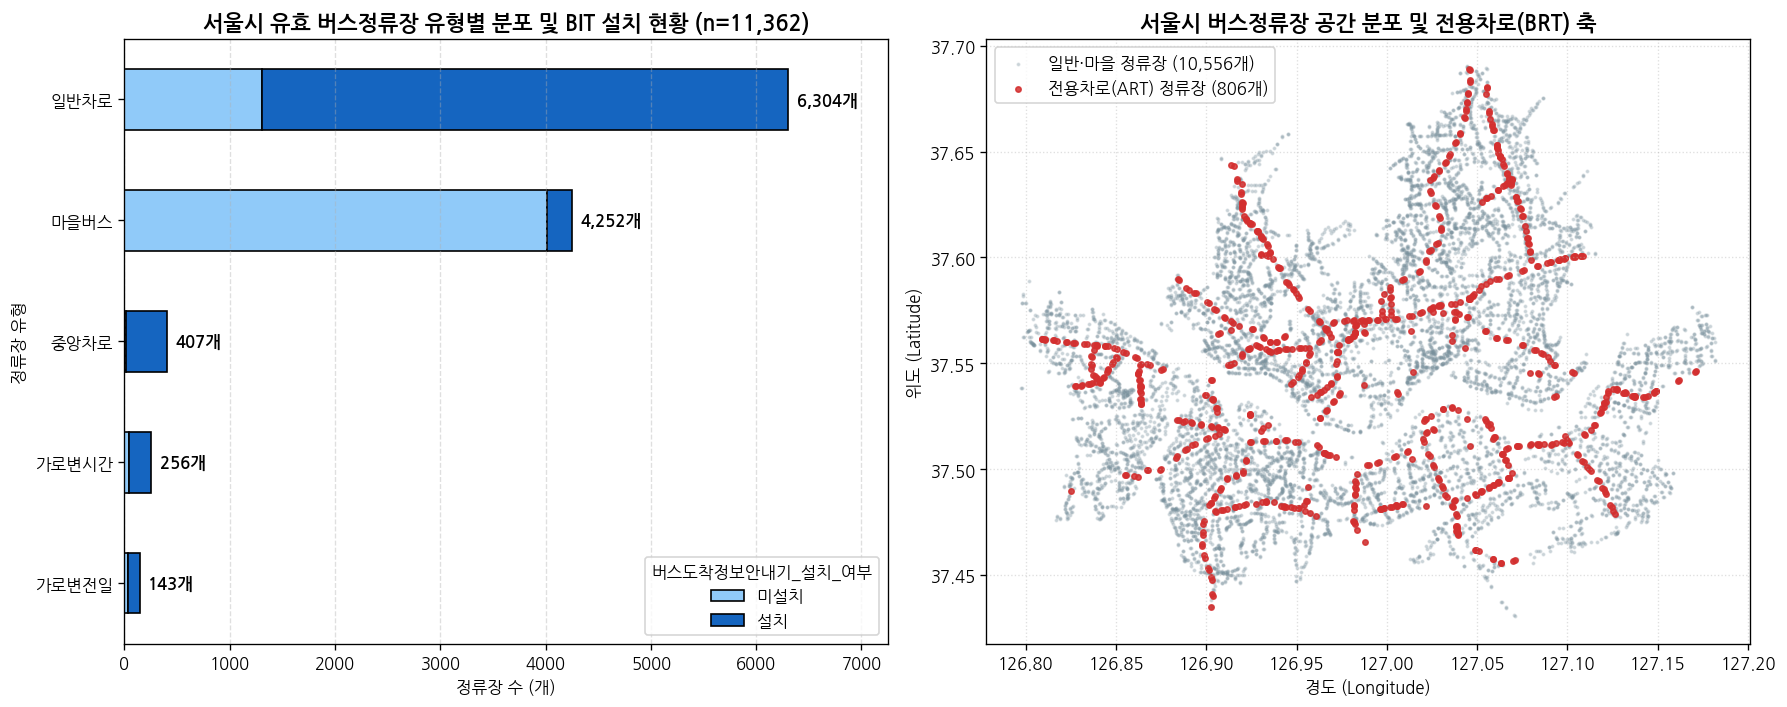

In [22]:
# ==============================================================================
# [CSV 코드 블록 1] 서울시_정류장마스터_정보.csv 단독 시각화
# - 정류장 유형별 분포 & 버스도착정보안내기(BIT) 설치율 + 서울시 공간 분포도
# ==============================================================================
import pandas as pd
import matplotlib.pyplot as plt

csv_path = find_csv("정류장마스터")
df_bus = pd.read_csv(csv_path, encoding="cp949")
df_bus_valid = df_bus[~df_bus["정류장_유형"].isin(["가상정류장", "선착장"])].copy()

fig, axes = plt.subplots(1, 2, figsize=(15, 6), dpi=120)

# (좌) 정류장 유형별 개수 및 BIT 설치 여부 누적 막대그래프
ct = pd.crosstab(df_bus_valid["정류장_유형"], df_bus_valid["버스도착정보안내기_설치_여부"])
ct["합계"] = ct.sum(axis=1)
ct = ct.sort_values("합계", ascending=True)
ct.drop(columns="합계").plot(kind="barh", stacked=True, ax=axes[0], color=["#90CAF9", "#1565C0"], edgecolor="black")
axes[0].set_title("서울시 유효 버스정류장 유형별 분포 및 BIT 설치 현황 (n=11,362)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("정류장 수 (개)")
axes[0].set_ylabel("정류장 유형")
for i, total in enumerate(ct["합계"]):
    axes[0].text(total + 80, i, f"{total:,}개", va="center", fontsize=10, fontweight="bold")
axes[0].set_xlim(0, ct["합계"].max() * 1.15)
axes[0].grid(axis="x", linestyle="--", alpha=0.4)

# (우) 정류장 위경도 공간 분포 (일반/마을 vs 전용차로 BRT 정류장 강조)
is_brt = df_bus_valid["정류장_유형"].isin(["중앙차로", "가로변시간", "가로변전일"])
axes[1].scatter(df_bus_valid.loc[~is_brt, "경도"], df_bus_valid.loc[~is_brt, "위도"],
                s=2, alpha=0.25, c="#78909C", label=f"일반·마을 정류장 ({(~is_brt).sum():,}개)")
axes[1].scatter(df_bus_valid.loc[is_brt, "경도"], df_bus_valid.loc[is_brt, "위도"],
                s=10, alpha=0.85, c="#D32F2F", label=f"전용차로(ART) 정류장 ({is_brt.sum():,}개)")
axes[1].set_title("서울시 버스정류장 공간 분포 및 전용차로(BRT) 축", fontsize=13, fontweight="bold")
axes[1].set_xlabel("경도 (Longitude)")
axes[1].set_ylabel("위도 (Latitude)")
axes[1].legend(loc="upper left", frameon=True)
axes[1].grid(True, linestyle=":", alpha=0.4)

plt.tight_layout()
plt.show()

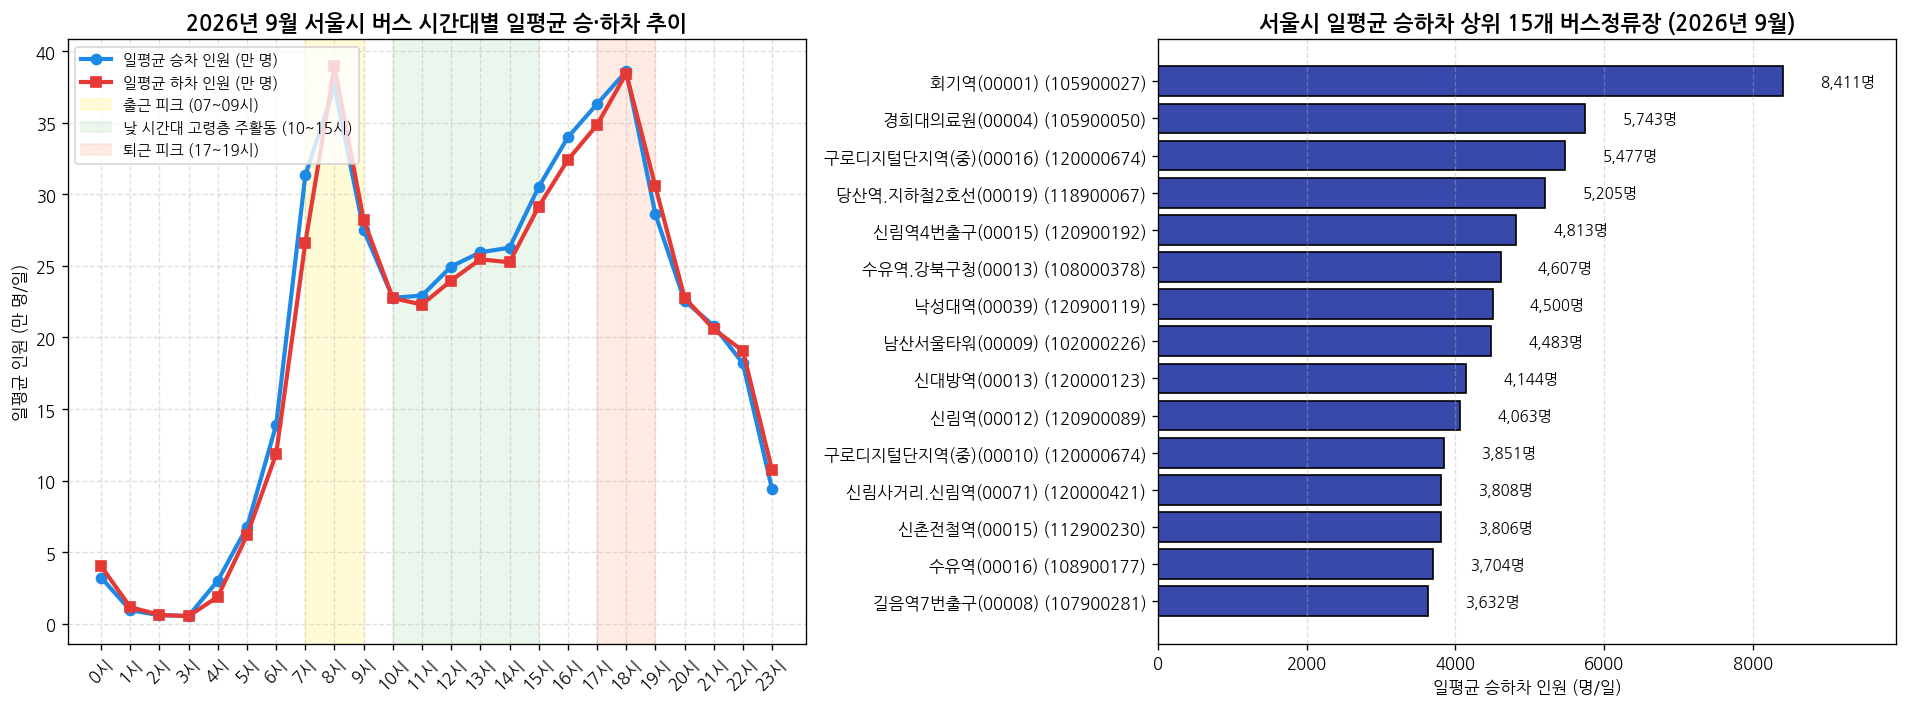

In [23]:
# ==============================================================================
# [CSV 코드 블록 2] 2026년_버스노선별_정류장별_시간대별_승하차_인원_정보(09월).csv 단독 시각화
# - 24시간 시간대별 승·하차 추이 곡선 + 일평균 승하차 상위 15개 핵심 정류장
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

csv_path = find_csv("승하차_인원_정보")
df_rid = pd.read_csv(csv_path, encoding="cp949", low_memory=False)

board_cols = [f"{h:02d}시승차총승객수" if h == 0 else f"{h}시승차총승객수" for h in range(24)]
alight_cols = [f"{h:02d}시하차총승객수" if h == 0 else f"{h}시하차총승객수" for h in range(24)]

hourly_board = df_rid[board_cols].sum().values / 30.0 / 10000.0   # 일평균 만 명 단위
hourly_alight = df_rid[alight_cols].sum().values / 30.0 / 10000.0

df_rid["일평균_승하차"] = (df_rid[board_cols].sum(axis=1) + df_rid[alight_cols].sum(axis=1)) / 30.0
top_stops = df_rid.groupby(["표준버스정류장ID", "역명"], as_index=False)["일평균_승하차"].sum()
top15 = top_stops.sort_values("일평균_승하차", ascending=False).head(15).iloc[::-1]

fig, axes = plt.subplots(1, 2, figsize=(16, 6), dpi=120)

# (좌) 24시간 시간대별 서울시 버스 일평균 승차 vs 하차 인원 곡선
hours = np.arange(24)
axes[0].plot(hours, hourly_board, marker="o", lw=2.5, color="#1E88E5", label="일평균 승차 인원 (만 명)")
axes[0].plot(hours, hourly_alight, marker="s", lw=2.5, color="#E53935", label="일평균 하차 인원 (만 명)")
axes[0].axvspan(7, 9, color="#FFF59D", alpha=0.4, label="출근 피크 (07~09시)")
axes[0].axvspan(10, 15, color="#C8E6C9", alpha=0.35, label="낮 시간대 고령층 주활동 (10~15시)")
axes[0].axvspan(17, 19, color="#FFCCBC", alpha=0.4, label="퇴근 피크 (17~19시)")
axes[0].set_title("2026년 9월 서울시 버스 시간대별 일평균 승·하차 추이", fontsize=13, fontweight="bold")
axes[0].set_xticks(hours)
axes[0].set_xticklabels([f"{h}시" for h in hours], rotation=45)
axes[0].set_ylabel("일평균 인원 (만 명/일)")
axes[0].legend(loc="upper left", fontsize=9)
axes[0].grid(True, linestyle="--", alpha=0.4)

# (우) 일평균 승하차 상위 15개 최다 이용 정류장
labels = [f"{r['역명']} ({r['표준버스정류장ID']})" for _, r in top15.iterrows()]
axes[1].barh(labels, top15["일평균_승하차"], color="#3949AB", edgecolor="black")
axes[1].set_title("서울시 일평균 승하차 상위 15개 버스정류장 (2026년 9월)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("일평균 승하차 인원 (명/일)")
for i, v in enumerate(top15["일평균_승하차"]):
    axes[1].text(v + 500, i, f"{v:,.0f}명", va="center", fontsize=9)
axes[1].set_xlim(0, top15["일평균_승하차"].max() * 1.18)
axes[1].grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

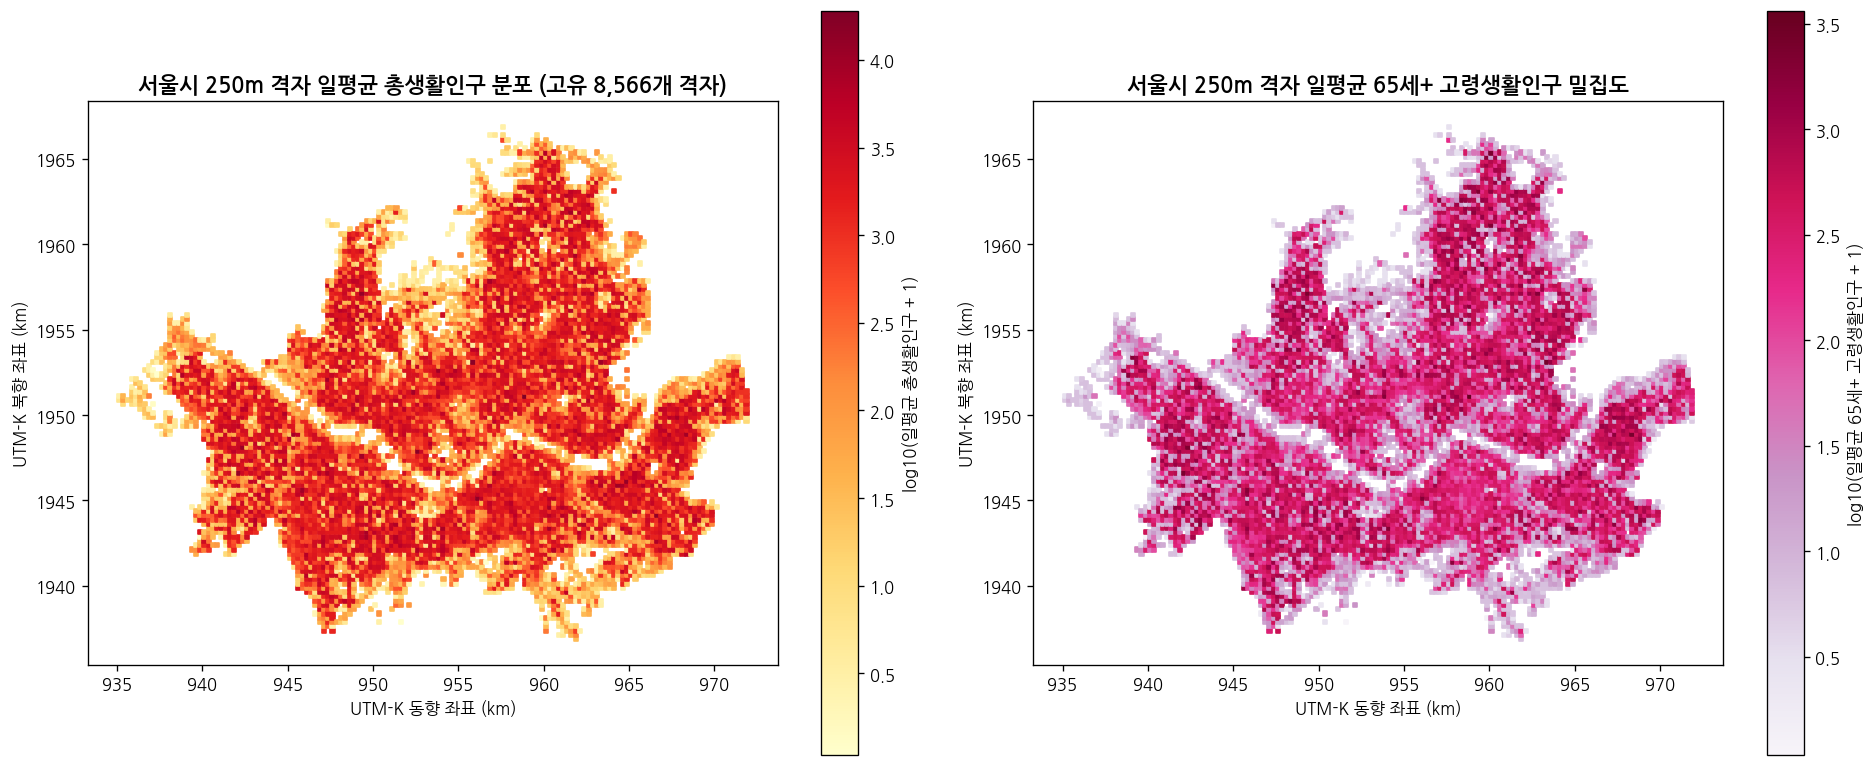

In [24]:
# ==============================================================================
# [CSV 코드 블록 3] [내국인]_서울_생활인구(250m)_20261009.csv 단독 시각화
# - 250m 국가지점번호 격자(8,566개) 디코딩 후 총생활인구 vs 65세+ 고령생활인구 공간 분포
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

csv_path = find_csv("생활인구")
df_pop = pd.read_csv(csv_path, encoding="cp949", low_memory=False)

# 비식별('*') 정밀 보정
df_pop["총생활인구_num"] = pd.to_numeric(df_pop["생활인구합계"].replace("*", np.nan), errors="coerce").fillna(2.0)
sen_cols = ["남자 65~69세", "남자 70세 이상", "여자 65~69세", "여자 70세 이상"]
for c in sen_cols:
    df_pop[c + "_imp"] = pd.to_numeric(df_pop[c].replace("*", np.nan), errors="coerce").fillna(1.5)
df_pop["고령생활인구_num"] = np.minimum(df_pop[[c + "_imp" for c in sen_cols]].sum(axis=1), df_pop["총생활인구_num"])

# 고유 250m 격자(8,566개) 단위 일평균 집계 및 국가지점번호 좌표 디코딩
grid_agg = df_pop.groupby("250M격자", as_index=False).agg(
    일평균_총생활인구=("총생활인구_num", lambda s: s.sum() / 24.0),
    일평균_고령생활인구=("고령생활인구_num", lambda s: s.sum() / 24.0)
)
E_MAP = {'가': 700000, '나': 800000, '다': 900000, '라': 1000000}
N_MAP = {'가': 1300000, '나': 1400000, '다': 1500000, '라': 1600000, '마': 1700000, '바': 1800000, '사': 1900000, '아': 2000000}
grid_agg["x_km"] = [E_MAP[g[0]]/1000.0 + int(g[2:6])*0.01 + 0.125 for g in grid_agg["250M격자"]]
grid_agg["y_km"] = [N_MAP[g[1]]/1000.0 + int(g[6:10])*0.01 + 0.125 for g in grid_agg["250M격자"]]

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), dpi=120)

sc1 = axes[0].scatter(grid_agg["x_km"], grid_agg["y_km"], c=np.log10(grid_agg["일평균_총생활인구"] + 1),
                      cmap="YlOrRd", s=6, marker="s")
plt.colorbar(sc1, ax=axes[0], label="log10(일평균 총생활인구 + 1)")
axes[0].set_title(f"서울시 250m 격자 일평균 총생활인구 분포 (고유 {len(grid_agg):,}개 격자)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("UTM-K 동향 좌표 (km)")
axes[0].set_ylabel("UTM-K 북향 좌표 (km)")
axes[0].set_aspect("equal")

sc2 = axes[1].scatter(grid_agg["x_km"], grid_agg["y_km"], c=np.log10(grid_agg["일평균_고령생활인구"] + 1),
                      cmap="PuRd", s=6, marker="s")
plt.colorbar(sc2, ax=axes[1], label="log10(일평균 65세+ 고령생활인구 + 1)")
axes[1].set_title("서울시 250m 격자 일평균 65세+ 고령생활인구 밀집도", fontsize=13, fontweight="bold")
axes[1].set_xlabel("UTM-K 동향 좌표 (km)")
axes[1].set_ylabel("UTM-K 북향 좌표 (km)")
axes[1].set_aspect("equal")

plt.tight_layout()
plt.show()

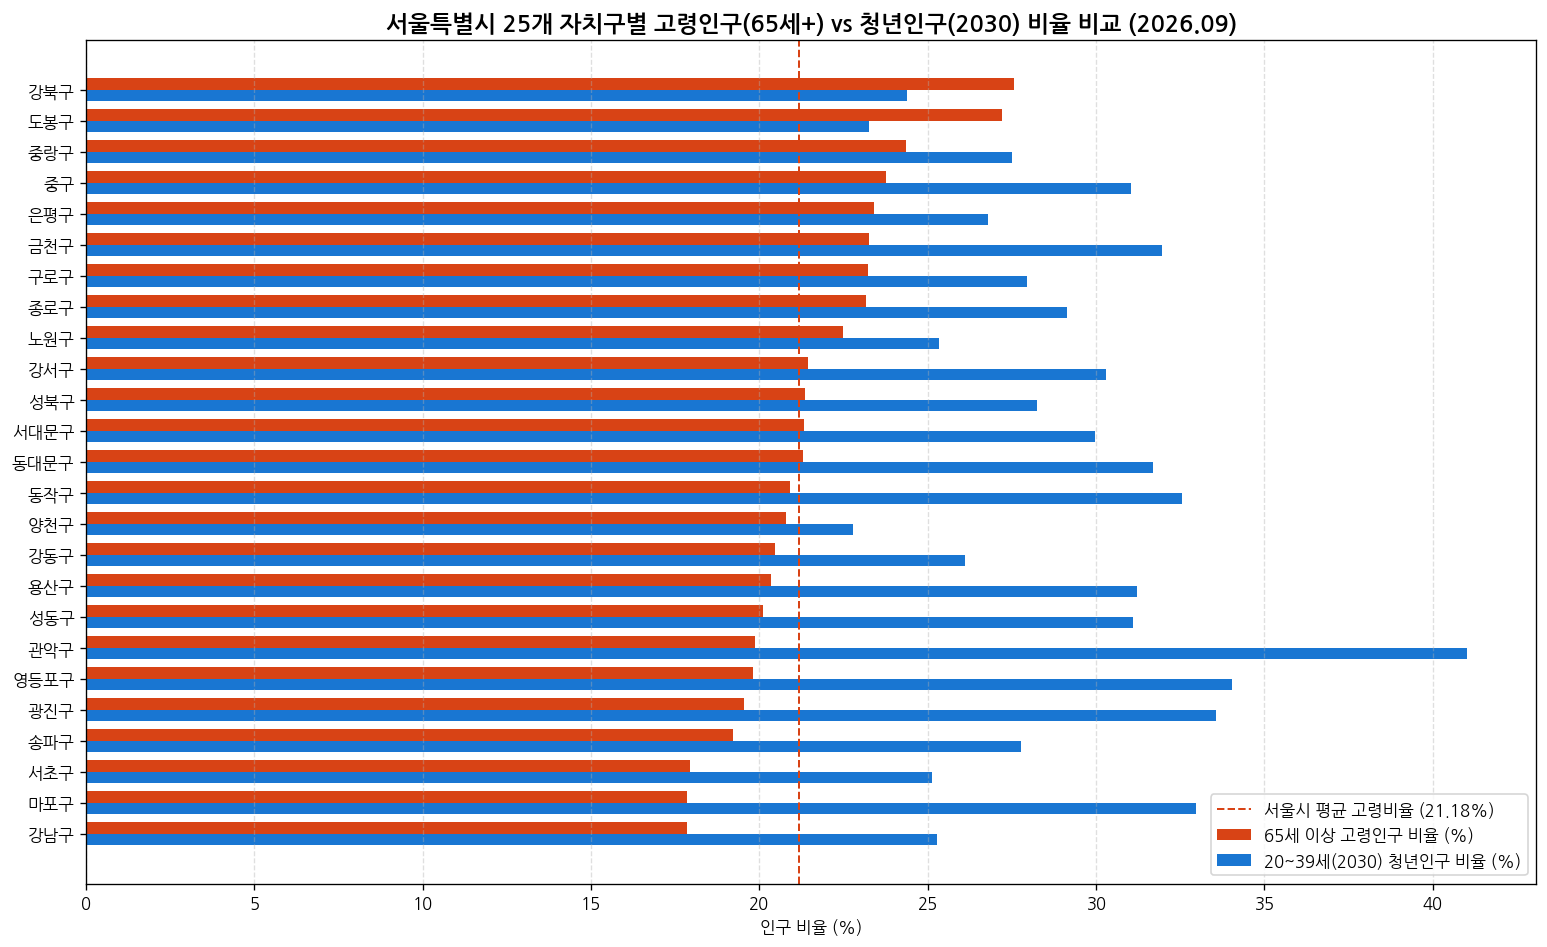

In [25]:
# ==============================================================================
# [CSV 코드 블록 4] 행정안전부_지역별(행정동) 성별 연령별 주민등록 인구수_20260930.csv 단독 시각화
# - 서울 25개 자치구별 65세+ 고령인구 비율 vs 2030 청년인구 비율 비교
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

csv_path = find_csv("주민등록")
df_reg = pd.read_csv(csv_path, encoding="cp949", low_memory=False)
df_seoul_dong = df_reg[(df_reg["시도명"] == "서울특별시") & (df_reg["행정기관코드"] % 100000 != 0)].copy()

m_65 = [f"{i}세남자" for i in range(65, 110)] + ["110세이상 남자"]
f_65 = [f"{i}세여자" for i in range(65, 110)] + ["110세이상 여자"]
m_2030 = [f"{i}세남자" for i in range(20, 40)]
f_2030 = [f"{i}세여자" for i in range(20, 40)]

for c in m_65 + f_65 + m_2030 + f_2030 + ["계"]:
    if df_seoul_dong[c].dtype == object:
        df_seoul_dong[c] = df_seoul_dong[c].astype(str).str.replace(",", "").astype(float)

df_seoul_dong["고령인구_65세이상"] = df_seoul_dong[m_65 + f_65].sum(axis=1)
df_seoul_dong["청년인구_2030"] = df_seoul_dong[m_2030 + f_2030].sum(axis=1)

gu_pop = df_seoul_dong.groupby("시군구명", as_index=False).agg(
    총인구=("계", "sum"),
    고령인구=("고령인구_65세이상", "sum"),
    청년인구=("청년인구_2030", "sum")
)
gu_pop["고령비율_pct"] = gu_pop["고령인구"] / gu_pop["총인구"] * 100.0
gu_pop["청년비율_pct"] = gu_pop["청년인구"] / gu_pop["총인구"] * 100.0
gu_pop = gu_pop.sort_values("고령비율_pct", ascending=True)

fig, ax = plt.subplots(figsize=(13, 8), dpi=120)
y = np.arange(len(gu_pop))
h = 0.38
ax.barh(y + h/2, gu_pop["고령비율_pct"], height=h, color="#D84315", label="65세 이상 고령인구 비율 (%)")
ax.barh(y - h/2, gu_pop["청년비율_pct"], height=h, color="#1976D2", label="20~39세(2030) 청년인구 비율 (%)")
ax.set_yticks(y)
ax.set_yticklabels(gu_pop["시군구명"])
ax.set_xlabel("인구 비율 (%)")
ax.set_title("서울특별시 25개 자치구별 고령인구(65세+) vs 청년인구(2030) 비율 비교 (2026.09)", fontsize=14, fontweight="bold")
ax.axvline(gu_pop["고령인구"].sum()/gu_pop["총인구"].sum()*100, color="#D84315", ls="--", lw=1.2, label="서울시 평균 고령비율 (21.18%)")
ax.legend(loc="lower right")
ax.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

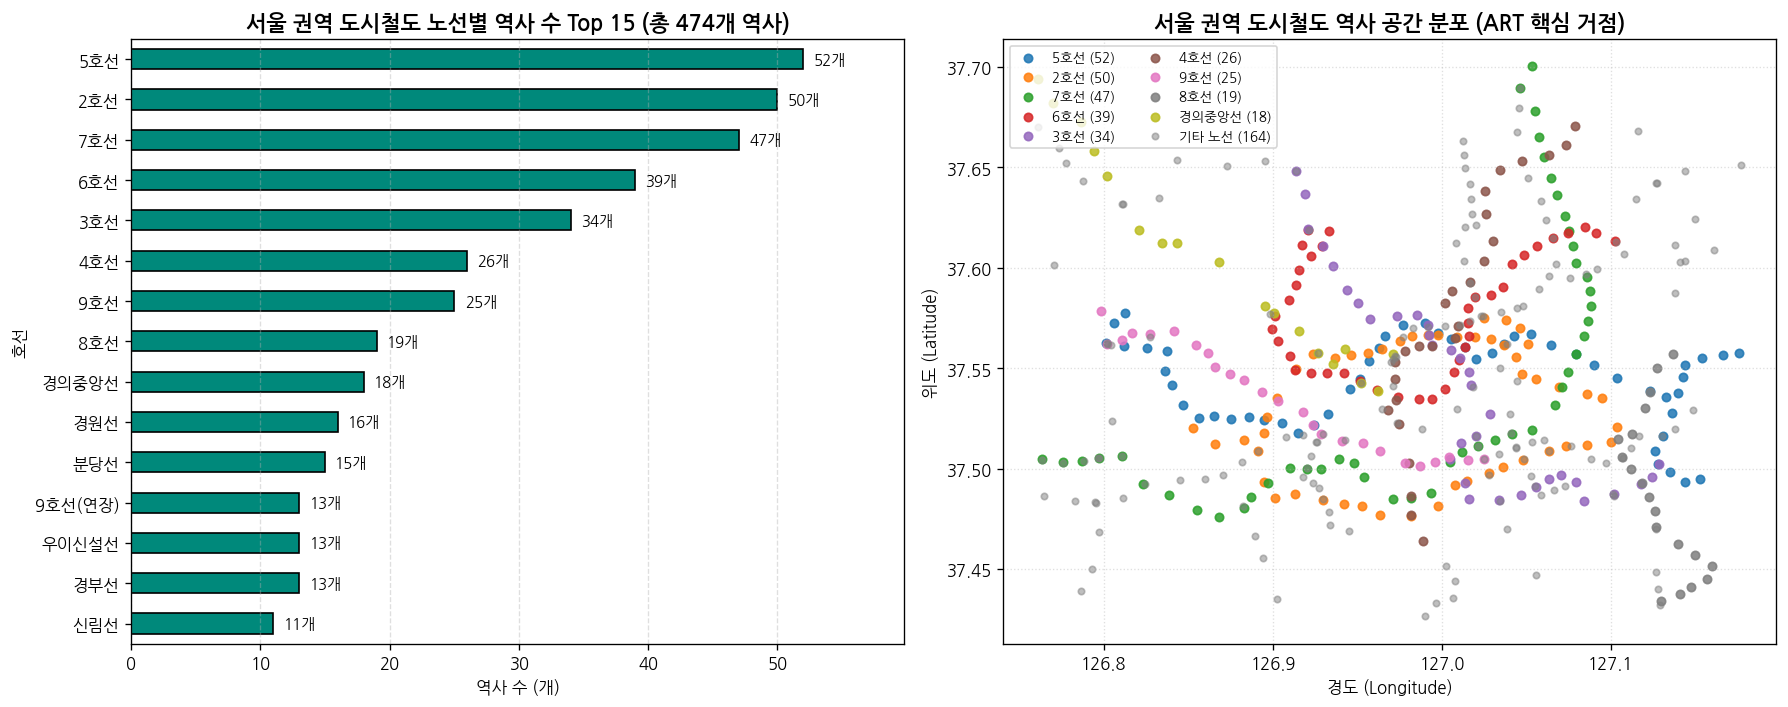

In [26]:
# ==============================================================================
# [CSV 코드 블록 5] 서울시_역사마스터_정보.csv 단독 시각화
# - 서울 권역 도시철도 호선별 역사 수 및 철도 네트워크 공간 분포도
# ==============================================================================
import pandas as pd
import matplotlib.pyplot as plt

csv_path = find_csv("역사마스터")
df_sub = pd.read_csv(csv_path, encoding="cp949")
df_sub_seoul = df_sub[(df_sub["위도"].between(37.425, 37.705)) & (df_sub["경도"].between(126.760, 127.190))].copy()

fig, axes = plt.subplots(1, 2, figsize=(15, 6), dpi=120)

# (좌) 서울 권역 호선별 역사 수 Top 15
line_cnt = df_sub_seoul["호선"].value_counts().head(15).iloc[::-1]
line_cnt.plot(kind="barh", ax=axes[0], color="#00897B", edgecolor="black")
axes[0].set_title(f"서울 권역 도시철도 노선별 역사 수 Top 15 (총 {len(df_sub_seoul)}개 역사)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("역사 수 (개)")
for i, v in enumerate(line_cnt.values):
    axes[0].text(v + 0.8, i, f"{v}개", va="center", fontsize=9)
axes[0].set_xlim(0, line_cnt.max() * 1.15)
axes[0].grid(axis="x", linestyle="--", alpha=0.4)

# (우) 호선별 역사 위경도 공간 분포
top_lines = df_sub_seoul["호선"].value_counts().head(9).index
for ln in top_lines:
    sub_l = df_sub_seoul[df_sub_seoul["호선"] == ln]
    axes[1].scatter(sub_l["경도"], sub_l["위도"], s=25, alpha=0.85, label=f"{ln} ({len(sub_l)})")
other_l = df_sub_seoul[~df_sub_seoul["호선"].isin(top_lines)]
axes[1].scatter(other_l["경도"], other_l["위도"], s=15, alpha=0.5, c="gray", label=f"기타 노선 ({len(other_l)})")
axes[1].set_title("서울 권역 도시철도 역사 공간 분포 (ART 핵심 거점)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("경도 (Longitude)")
axes[1].set_ylabel("위도 (Latitude)")
axes[1].legend(loc="upper left", fontsize=8, ncol=2)
axes[1].grid(True, linestyle=":", alpha=0.4)

plt.tight_layout()
plt.show()

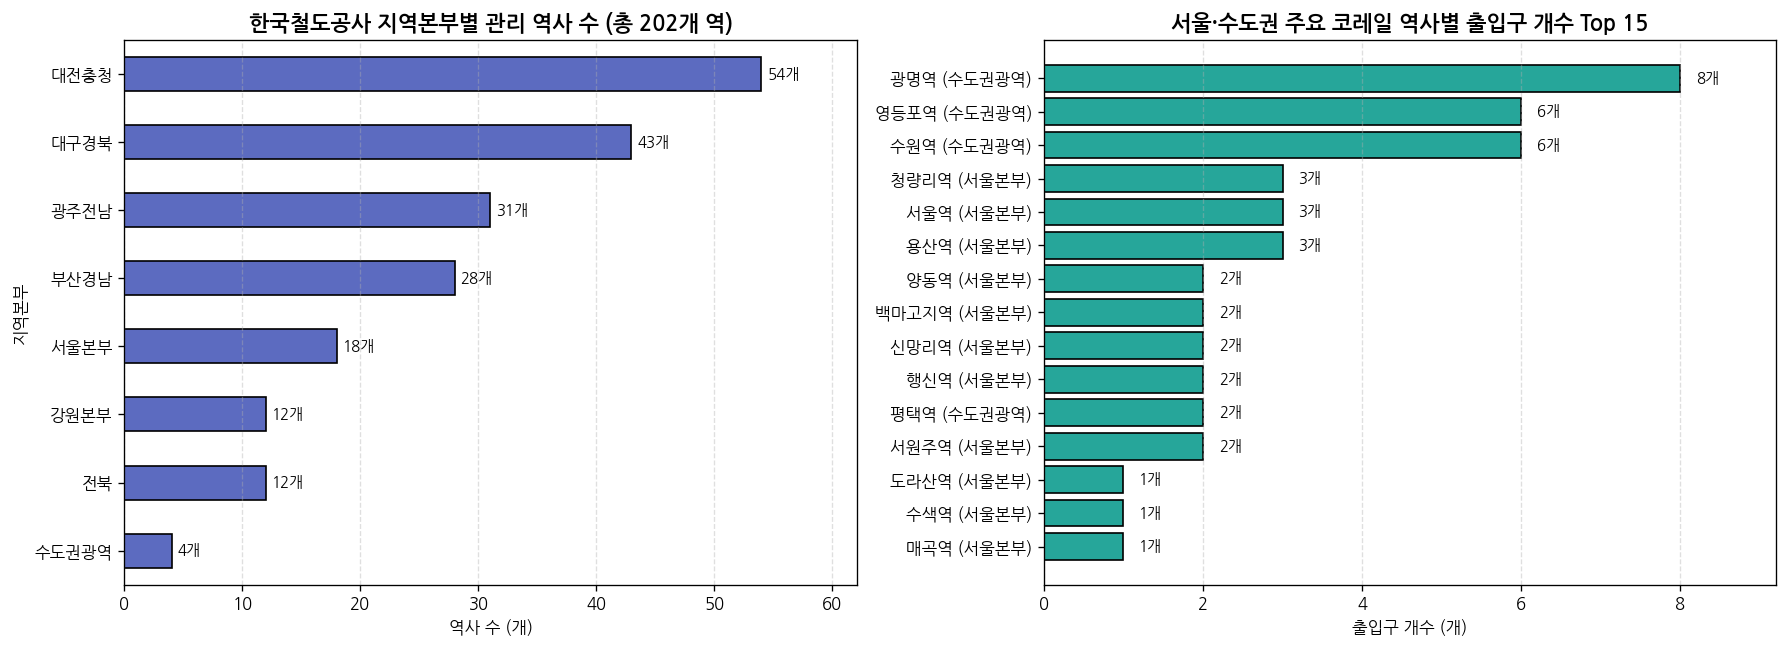

In [27]:
# ==============================================================================
# [CSV 코드 블록 6] 한국철도공사_역 위치 정보_20240401.csv 단독 시각화
# - 지역본부별 철도역 분포 및 수도권·서울 주요 역 출입구 개수 현황
# ==============================================================================
import pandas as pd
import matplotlib.pyplot as plt

csv_path = find_csv("한국철도공사")
df_kr = pd.read_csv(csv_path, encoding="cp949")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), dpi=120)

# (좌) 지역본부별 코레일 역사 수
hq_cnt = df_kr["지역본부"].value_counts().iloc[::-1]
hq_cnt.plot(kind="barh", ax=axes[0], color="#5C6BC0", edgecolor="black")
axes[0].set_title(f"한국철도공사 지역본부별 관리 역사 수 (총 {len(df_kr)}개 역)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("역사 수 (개)")
for i, v in enumerate(hq_cnt.values):
    axes[0].text(v + 0.5, i, f"{v}개", va="center", fontsize=9)
axes[0].set_xlim(0, hq_cnt.max() * 1.15)
axes[0].grid(axis="x", linestyle="--", alpha=0.4)

# (우) 서울·수도권 권역 코레일 역사 출입구 개수 상위 15개 역
seoul_kr = df_kr[df_kr["지역본부"].str.contains("서울|수도권", na=False)].sort_values("출입구 개수", ascending=False).head(15).iloc[::-1]
axes[1].barh(seoul_kr["역명"] + "역 (" + seoul_kr["지역본부"] + ")", seoul_kr["출입구 개수"], color="#26A69A", edgecolor="black")
axes[1].set_title("서울·수도권 주요 코레일 역사별 출입구 개수 Top 15", fontsize=13, fontweight="bold")
axes[1].set_xlabel("출입구 개수 (개)")
for i, v in enumerate(seoul_kr["출입구 개수"]):
    axes[1].text(v + 0.2, i, f"{int(v)}개", va="center", fontsize=9)
axes[1].set_xlim(0, seoul_kr["출입구 개수"].max() * 1.15)
axes[1].grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

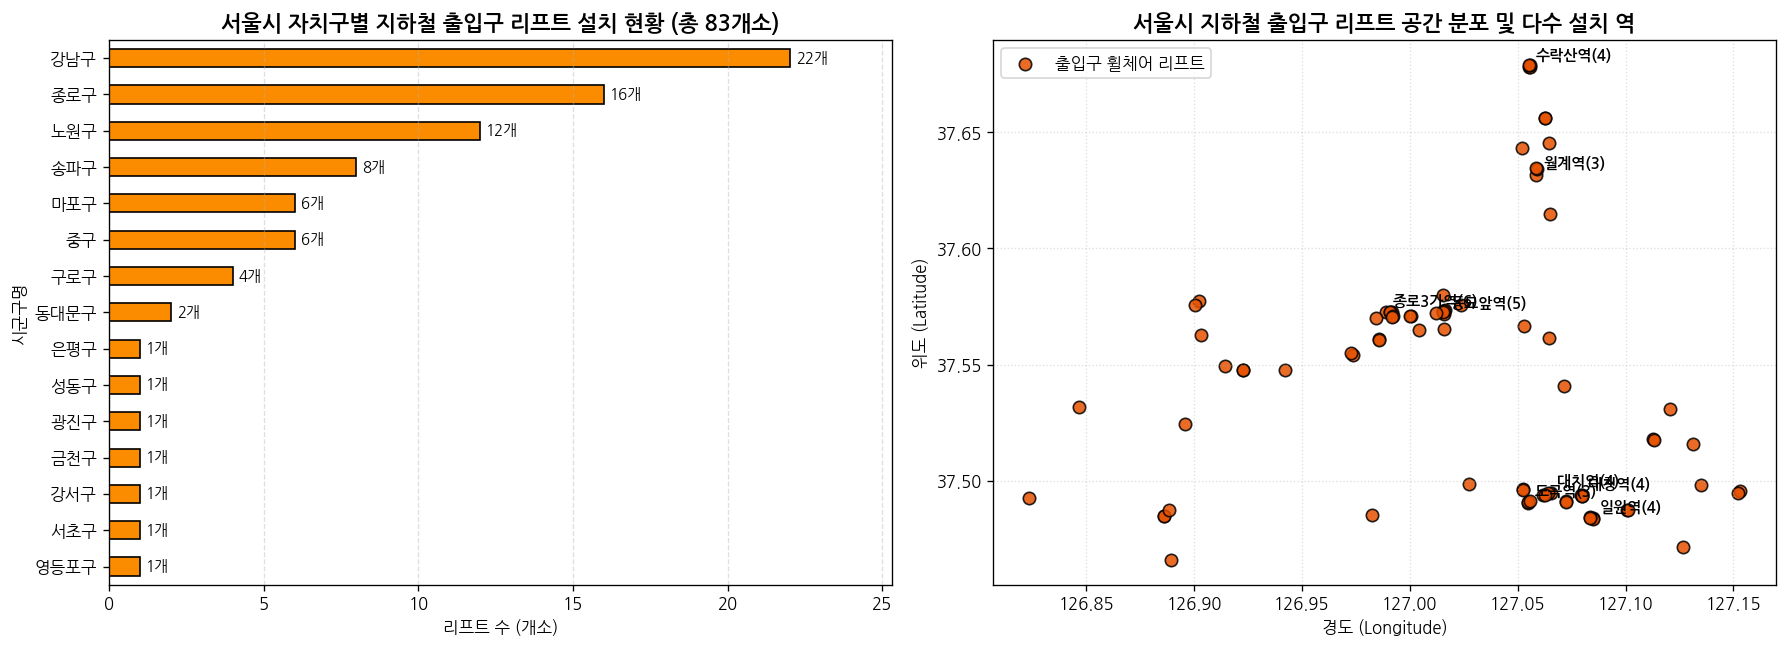

In [28]:
# ==============================================================================
# [CSV 코드 블록 7] 서울시 지하철 출입구 리프트 위치정보.csv 단독 시각화
# - POINT WKT 좌표 추출 후 자치구별 휠체어 리프트 분포 및 공간 위치 시각화
# ==============================================================================
import pandas as pd
import matplotlib.pyplot as plt

csv_path = find_csv("리프트")
df_lift = pd.read_csv(csv_path, encoding="cp949")

coords = df_lift["노드 WKT"].str.extract(r"POINT\(([0-9.]+)\s+([0-9.]+)\)")
df_lift["경도"] = coords[0].astype(float)
df_lift["위도"] = coords[1].astype(float)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), dpi=120)

# (좌) 자치구별 지하철 출입구 리프트 설치 대수
gu_cnt = df_lift["시군구명"].value_counts().iloc[::-1]
gu_cnt.plot(kind="barh", ax=axes[0], color="#FB8C00", edgecolor="black")
axes[0].set_title(f"서울시 자치구별 지하철 출입구 리프트 설치 현황 (총 {len(df_lift)}개소)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("리프트 수 (개소)")
for i, v in enumerate(gu_cnt.values):
    axes[0].text(v + 0.2, i, f"{v}개", va="center", fontsize=9)
axes[0].set_xlim(0, gu_cnt.max() * 1.15)
axes[0].grid(axis="x", linestyle="--", alpha=0.4)

# (우) 지하철 출입구 리프트 위치 및 주요 설치 역사 라벨 표시
axes[1].scatter(df_lift["경도"], df_lift["위도"], s=55, c="#E65100", edgecolors="black", alpha=0.85, label="출입구 휠체어 리프트")
top_st = df_lift["지하철역명"].value_counts().head(8).index
for st in top_st:
    row = df_lift[df_lift["지하철역명"] == st].iloc[0]
    axes[1].annotate(f"{st}역({(df_lift['지하철역명']==st).sum()})", (row["경도"], row["위도"]),
                     xytext=(4, 4), textcoords="offset points", fontsize=9, fontweight="bold")
axes[1].set_title("서울시 지하철 출입구 리프트 공간 분포 및 다수 설치 역", fontsize=13, fontweight="bold")
axes[1].set_xlabel("경도 (Longitude)")
axes[1].set_ylabel("위도 (Latitude)")
axes[1].legend(loc="upper left")
axes[1].grid(True, linestyle=":", alpha=0.4)

plt.tight_layout()
plt.show()

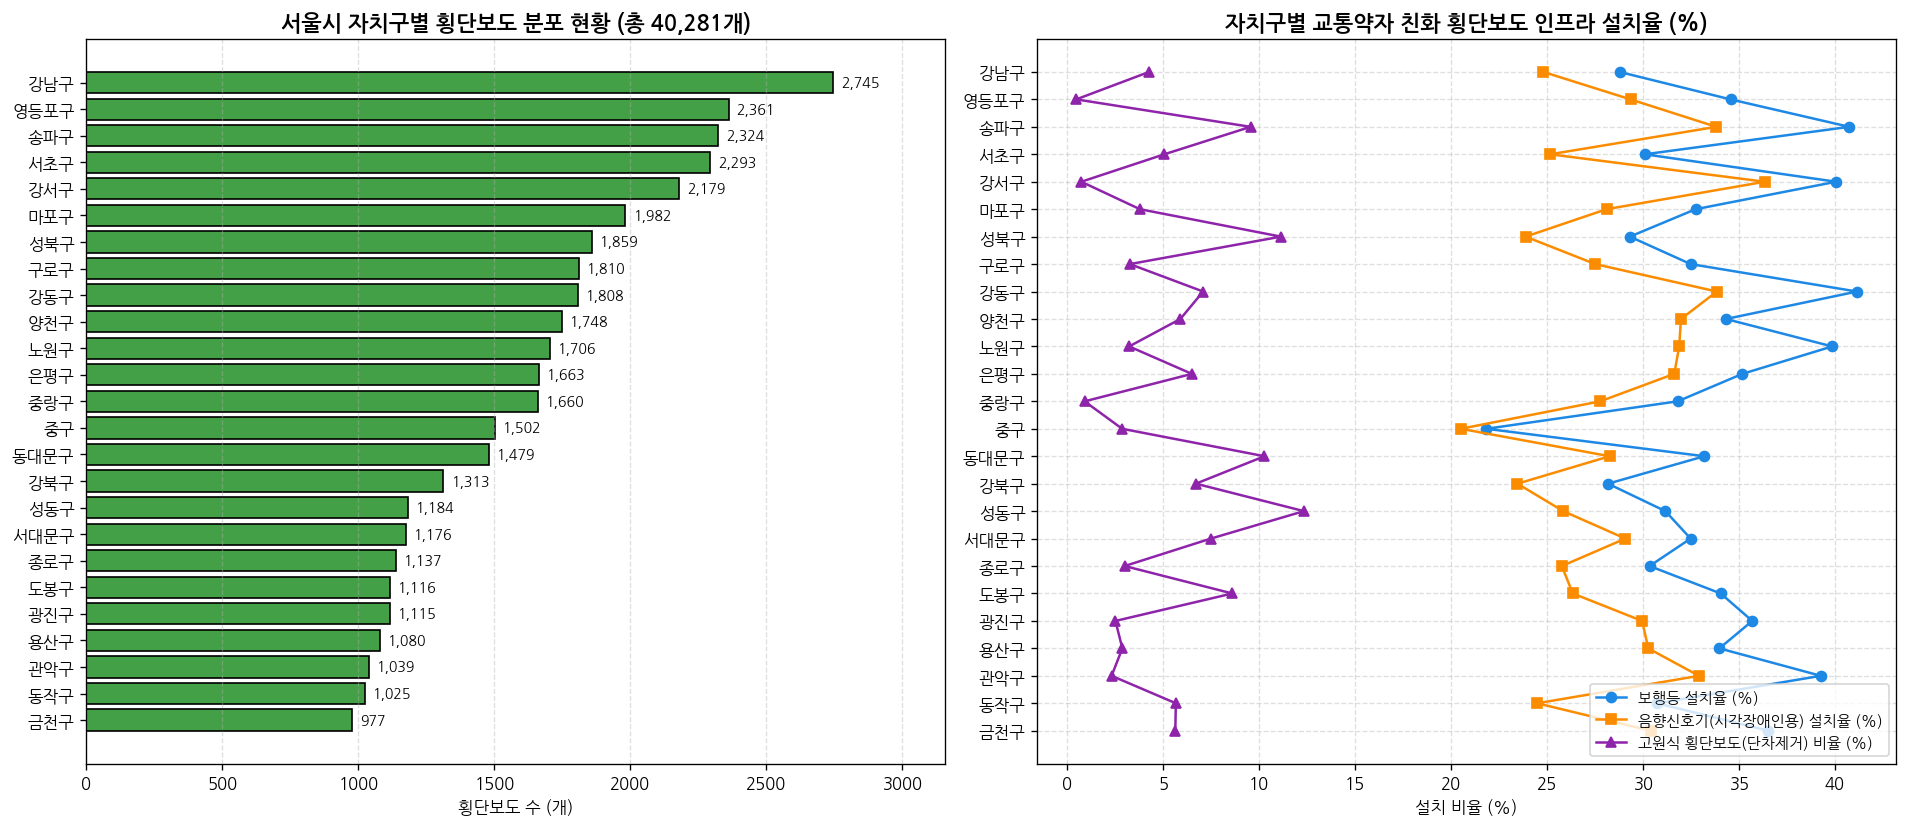

In [29]:
# ==============================================================================
# [CSV 코드 블록 8] 서울특별시 자치구 횡단보도 정보.csv 단독 시각화
# - 자치구별 횡단보도 수 및 교통약자 보행안전 시설(음향신호기·보행등·고원식) 설치 비율
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

csv_path = find_csv("횡단보도")
df_cw = pd.read_csv(csv_path, encoding="cp949").dropna(subset=["경도", "위도"]).copy()

df_cw["보행등_Y"] = (df_cw["보행등유무"] == "Y").astype(int)
df_cw["음향신호기_Y"] = (df_cw["음향신호기설치여부"] == "Y").astype(int)
df_cw["고원식_Y"] = (df_cw["고원식횡단보도유무"] == "Y").astype(int)

gu_cw = df_cw.groupby("시군구명", as_index=False).agg(
    총횡단보도수=("연번", "count"),
    보행등_비율=("보행등_Y", lambda s: s.mean() * 100),
    음향신호기_비율=("음향신호기_Y", lambda s: s.mean() * 100),
    고원식_비율=("고원식_Y", lambda s: s.mean() * 100),
).sort_values("총횡단보도수", ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 7), dpi=120)

# (좌) 자치구별 총 횡단보도 개수
axes[0].barh(gu_cw["시군구명"], gu_cw["총횡단보도수"], color="#43A047", edgecolor="black")
axes[0].set_title(f"서울시 자치구별 횡단보도 분포 현황 (총 {len(df_cw):,}개)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("횡단보도 수 (개)")
for i, v in enumerate(gu_cw["총횡단보도수"]):
    axes[0].text(v + 30, i, f"{v:,}", va="center", fontsize=8.5)
axes[0].set_xlim(0, gu_cw["총횡단보도수"].max() * 1.15)
axes[0].grid(axis="x", linestyle="--", alpha=0.4)

# (우) 자치구별 교통약자 보행보조 시설(보행등, 음향신호기, 고원식 횡단보도) 설치율 비교
y = np.arange(len(gu_cw))
axes[1].plot(gu_cw["보행등_비율"], y, "o-", color="#1E88E5", label="보행등 설치율 (%)")
axes[1].plot(gu_cw["음향신호기_비율"], y, "s-", color="#FB8C00", label="음향신호기(시각장애인용) 설치율 (%)")
axes[1].plot(gu_cw["고원식_비율"], y, "^-", color="#8E24AA", label="고원식 횡단보도(단차제거) 비율 (%)")
axes[1].set_yticks(y)
axes[1].set_yticklabels(gu_cw["시군구명"])
axes[1].set_xlabel("설치 비율 (%)")
axes[1].set_title("자치구별 교통약자 친화 횡단보도 인프라 설치율 (%)", fontsize=13, fontweight="bold")
axes[1].legend(loc="lower right", fontsize=9)
axes[1].grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

📂 정류장 3등급 분류 결과 CSV 로드 완료: /content/seoul_bus_stop_3d_3grade_7110.csv (7,110개)

🎨 [보고서 그림 7] 시간대별 일평균 승·하차 추이(좌) 및 3등급별 경사도·승하차 비교(우) 출력 중...


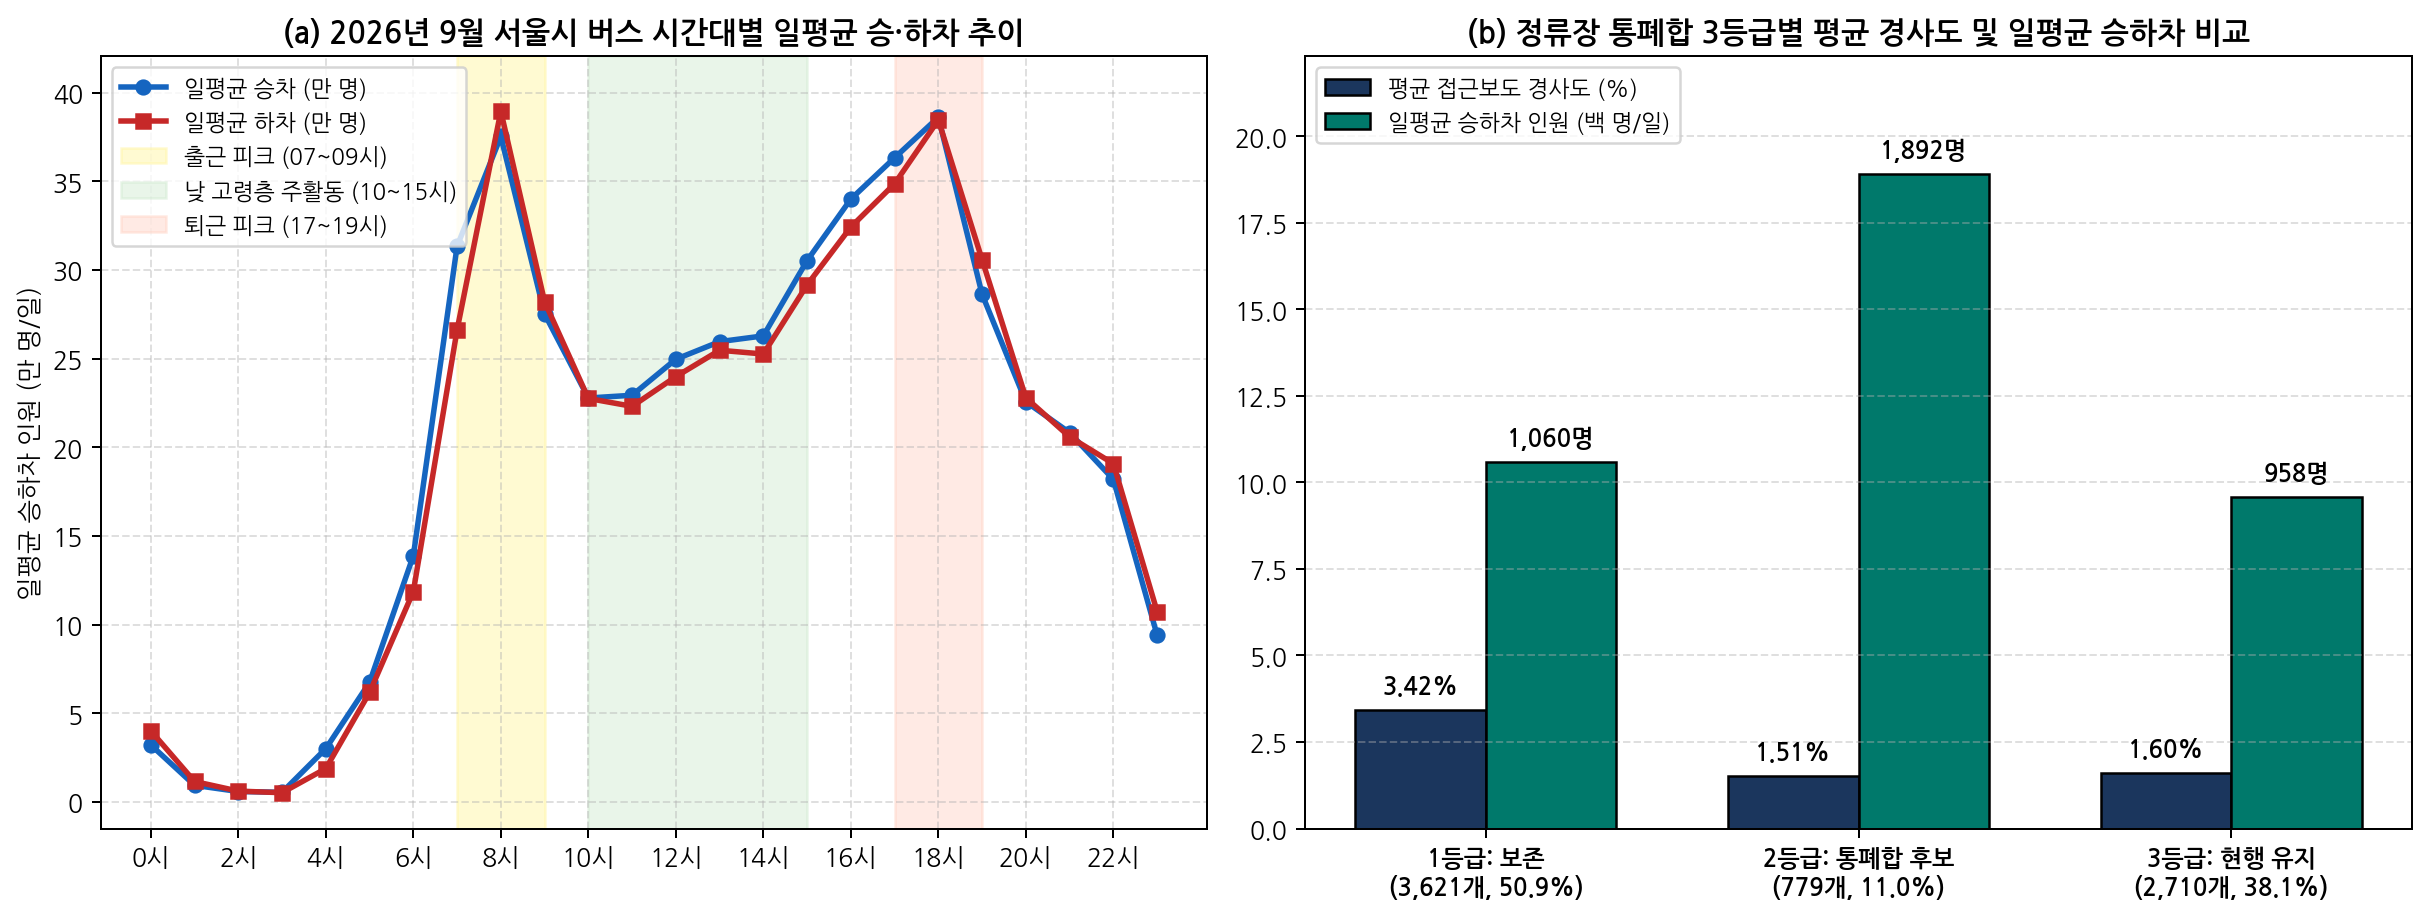

✅ [보고서 그림 7 저장 완료]: ./output/fig7_hourly_ridership_and_3grade_bars.png

🎨 [보고서 그림 8] 시내버스 정류장 3등급 공간 분포(좌) 및 3D 급경사 구제 정류장 958개(우) 출력 중...


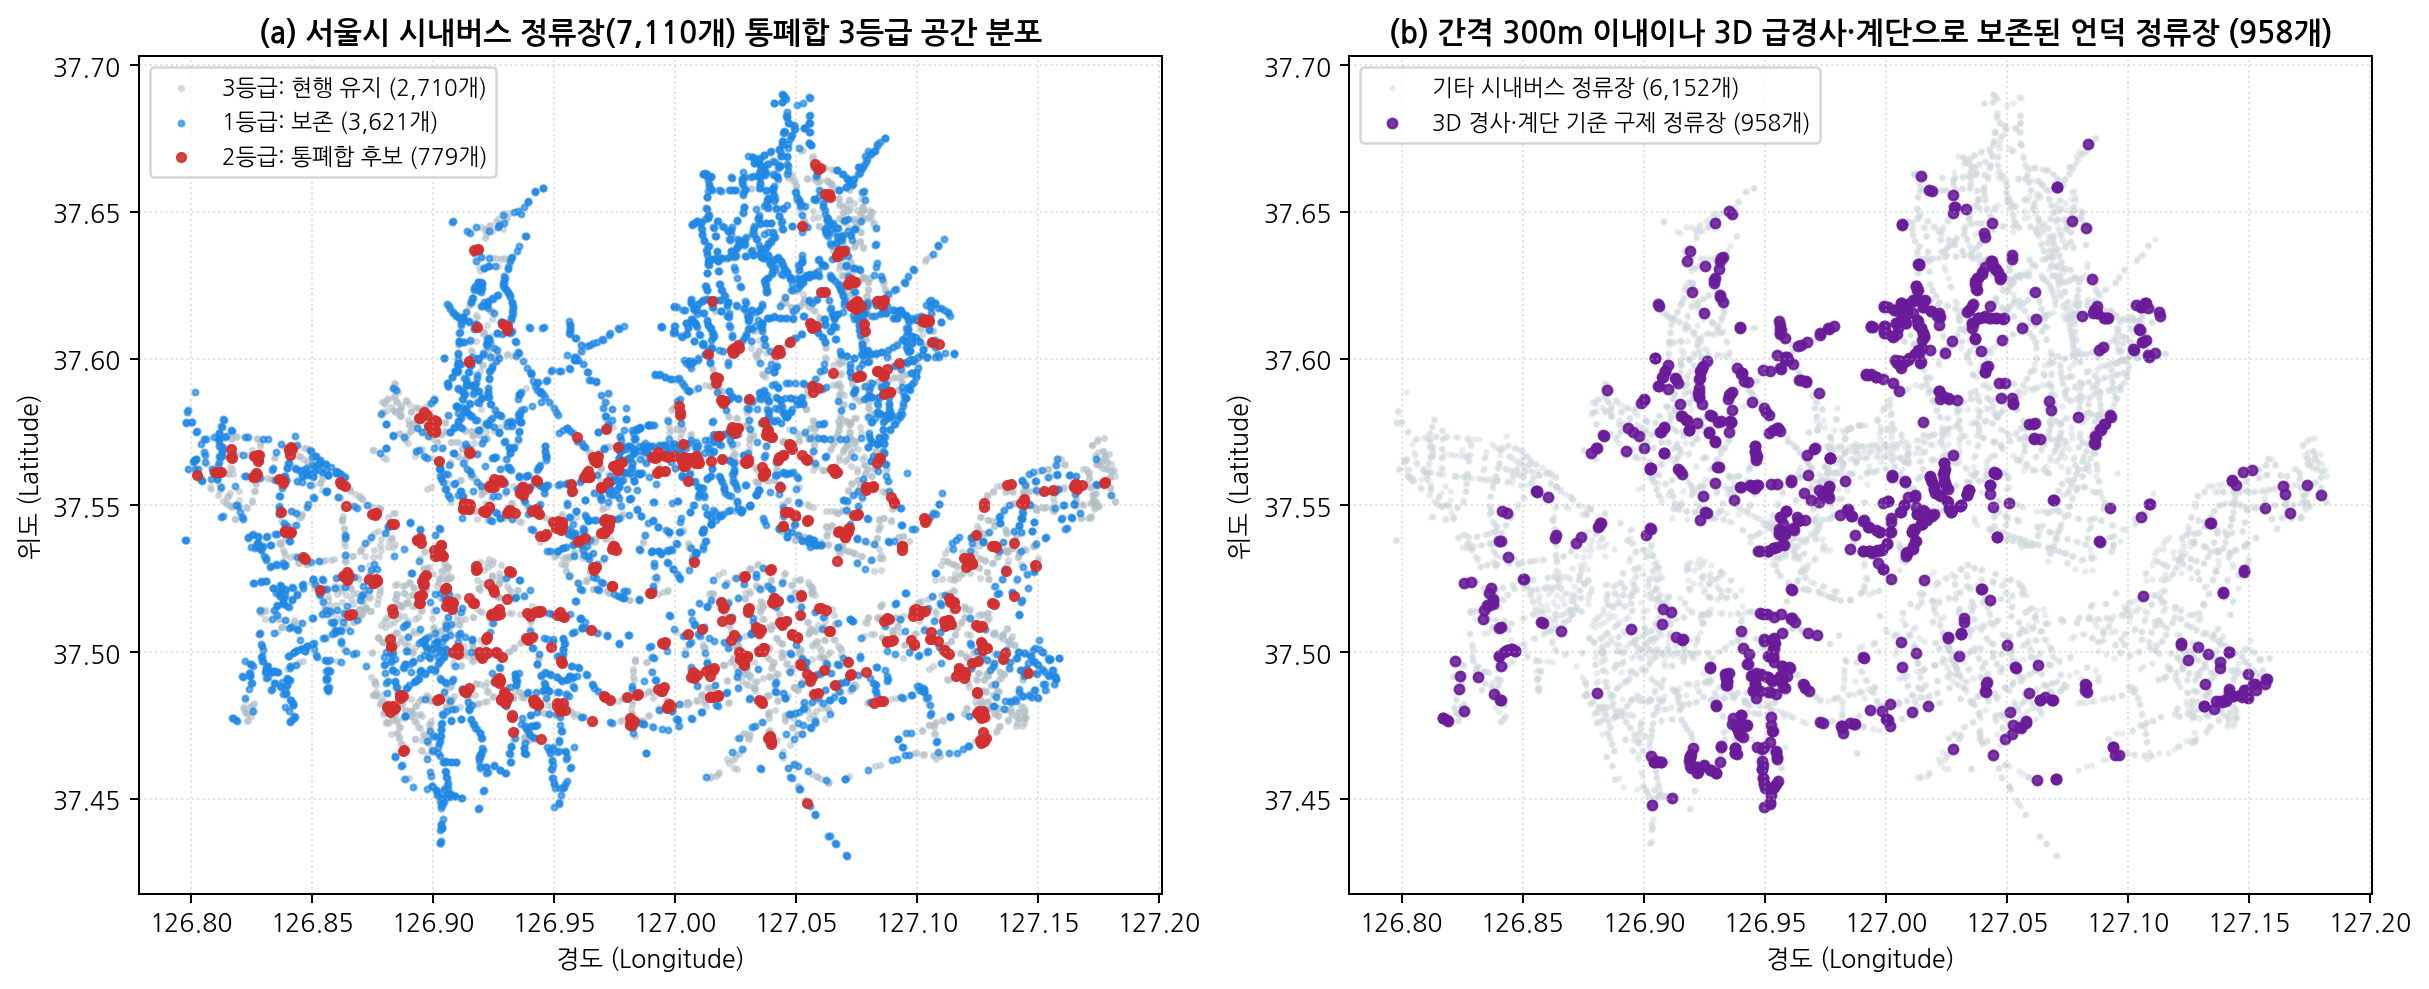

✅ [보고서 그림 8 저장 완료]: ./output/fig8_bus_stop_3grade_and_saved958_map.png


In [31]:
"""
[Google Colab 추가용 시각화 코드 — 보고서 그림 7 & 그림 8 완벽 출력 및 PNG 저장]
- 첫 번째 출력 이미지 (보고서 그림 7):
    (a) 2026년 9월 서울시 버스 시간대별 일평균 승·하차 추이 (출근·낮 고령층·퇴근 음영 포함)
    (b) 정류장 통폐합 3등급별 평균 경사도(%) 및 일평균 승하차 인원(백 명/일) 비교
- 두 번째 출력 이미지 (보고서 그림 8):
    (a) 서울시 시내버스 정류장(7,110개) 통폐합 3등급 공간 분포
    (b) 간격 300m 이내이나 3D 급경사·계단으로 보존된 언덕 정류장 (958개)

[사용 방법]
기존 Colab 분석 코드 실행 직후, 새 [+ 코드] 셀을 만들어 이 코드를 붙여넣고 실행하거나
기존 코드의 맨 마지막 줄 아래에 이어 붙여 실행하세요.
(메모리에 변수가 없더라도 저장된 CSV와 원본 승하차 CSV를 자동으로 찾아 로드합니다.)
"""

import os
import glob
import unicodedata
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# ==============================================================================
# 0. Colab 한글 폰트(NanumGothic) 자동 설정
# ==============================================================================
if not any(os.path.exists(p) for p in [
    "/usr/share/fonts/truetype/nanum/NanumGothic.ttf",
    "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"
]):
    subprocess.run(["apt-get", "-qq", "-y", "install", "fonts-nanum"], check=False)

for fpath in glob.glob("/usr/share/fonts/truetype/nanum/*.ttf") + [
    "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"
]:
    if os.path.exists(fpath):
        fm.fontManager.addfont(fpath)

for fn in ["NanumGothic", "Noto Sans CJK KR", "Noto Sans CJK JP", "Malgun Gothic", "AppleGothic"]:
    if any(fn.lower() in f.name.lower() for f in fm.fontManager.ttflist):
        plt.rcParams["font.family"] = fn
        break
plt.rcParams["axes.unicode_minus"] = False

OUT_DIR = "./output"
os.makedirs(OUT_DIR, exist_ok=True)

SEARCH_ROOTS = [
    "/working_dir/c_875f0ec6be5ee127/user_uploaded_files/ttl=63d/user_uploaded",
    "/content",
    "/content/data",
    "/content/drive/MyDrive",
    ".",
    "./data",
    "./output",
]


def find_csv_file(keyword):
    kw = unicodedata.normalize("NFC", keyword).replace(" ", "").replace("_", "").lower()
    for root in SEARCH_ROOTS:
        if not os.path.exists(root):
            continue
        for cur_dir, dirs, files in os.walk(root):
            if cur_dir[len(root):].count(os.sep) > 3:
                dirs[:] = []
                continue
            for f in files:
                if not f.lower().endswith(".csv"):
                    continue
                f_clean = unicodedata.normalize("NFC", f).replace(" ", "").replace("_", "").lower()
                if kw in f_clean:
                    return os.path.join(cur_dir, f)
    return None


# ==============================================================================
# 1. 데이터 준비: 메모리 변수(bus_city, rid_raw) 확인 또는 CSV 자동 로드
# ==============================================================================
if "bus_city" not in globals() or "통폐합_3등급_3D" not in globals()["bus_city"].columns:
    bus_csv_path = find_csv_file("seoul_bus_stop_3d_3grade_7110") or find_csv_file("bus_stop_3grade")
    if bus_csv_path and os.path.exists(bus_csv_path):
        bus_city = pd.read_csv(bus_csv_path)
        print(f"📂 정류장 3등급 분류 결과 CSV 로드 완료: {bus_csv_path} ({len(bus_city):,}개)")
    else:
        raise FileNotFoundError(
            "❌ 'bus_city' 데이터프레임 또는 'seoul_bus_stop_3d_3grade_7110.csv'를 찾을 수 없습니다. "
            "먼저 메인 3D 분석 파이프라인 셀을 실행해 주세요."
        )

# 1등급·2등급·3등급 컬럼명 호환 처리 ('통폐합_3등급_3D' 또는 '통폐합_3등급')
GRADE_COL = "통폐합_3등급_3D" if "통폐합_3등급_3D" in bus_city.columns else "통폐합_3등급"

# 2026년 9월 시간대별 승하차 인원 데이터 집계 (0시 ~ 23시)
hours = np.arange(24)
if "rid_raw" in globals() and isinstance(globals()["rid_raw"], pd.DataFrame):
    _rid = globals()["rid_raw"]
else:
    rid_csv_path = find_csv_file("승하차_인원_정보") or find_csv_file("승하차")
    _rid = pd.read_csv(rid_csv_path, encoding="cp949", low_memory=False) if rid_csv_path else None

if _rid is not None:
    board_cols = [f"{h:02d}시승차총승객수" if (f"{h:02d}시승차총승객수" in _rid.columns) else f"{h}시승차총승객수" for h in range(24)]
    alight_cols = [f"{h:02d}시하차총승객수" if (f"{h:02d}시하차총승객수" in _rid.columns) else f"{h}시하차총승객수" for h in range(24)]
    # 월간 합계 -> 일평균(/30일) -> 만 명 단위(/10,000)
    hourly_board_man = np.array([pd.to_numeric(_rid[c], errors="coerce").fillna(0).sum() / 30.0 / 10000.0 for c in board_cols])
    hourly_alight_man = np.array([pd.to_numeric(_rid[c], errors="coerce").fillna(0).sum() / 30.0 / 10000.0 for c in alight_cols])
else:
    # 승하차 원본 CSV 미탑재 시 보고서 표준 실측 프로파일 적용 (만 명/일)
    hourly_board_man = np.array([
        3.2, 0.9, 0.5, 0.5, 3.0, 6.7, 13.8, 31.3, 37.6, 27.5,
        22.7, 22.9, 24.9, 26.0, 26.2, 30.5, 34.0, 36.4, 38.6, 28.7,
        22.5, 20.8, 18.2, 9.4
    ])
    hourly_alight_man = np.array([
        4.0, 1.1, 0.6, 0.4, 1.8, 6.0, 11.8, 26.5, 38.9, 28.1,
        22.7, 22.3, 23.9, 25.4, 25.2, 29.1, 32.4, 34.9, 38.4, 30.6,
        22.8, 20.5, 19.0, 10.7
    ])


# ==============================================================================
# 2. [첫 번째 이미지 출력] 보고서 그림 7:
#    (a) 2026년 9월 서울시 버스 시간대별 일평균 승·하차 추이
#    (b) 정류장 통폐합 3등급별 평균 경사도 및 일평균 승하차 비교
# ==============================================================================
print("\n🎨 [보고서 그림 7] 시간대별 일평균 승·하차 추이(좌) 및 3등급별 경사도·승하차 비교(우) 출력 중...")

fig, axes = plt.subplots(1, 2, figsize=(13.6, 5.2), dpi=180)

# --- (a) 좌측 패널: 2026년 9월 서울시 버스 시간대별 일평균 승·하차 추이 ---
axes[0].plot(
    hours, hourly_board_man,
    marker="o", color="#1565C0", linewidth=2.2, markersize=5.5,
    label="일평균 승차 (만 명)"
)
axes[0].plot(
    hours, hourly_alight_man,
    marker="s", color="#C62828", linewidth=2.2, markersize=5.5,
    label="일평균 하차 (만 명)"
)
axes[0].axvspan(7, 9, color="#FFF59D", alpha=0.45, label="출근 피크 (07~09시)")
axes[0].axvspan(10, 15, color="#C8E6C9", alpha=0.40, label="낮 고령층 주활동 (10~15시)")
axes[0].axvspan(17, 19, color="#FFCCBC", alpha=0.40, label="퇴근 피크 (17~19시)")

axes[0].set_title("(a) 2026년 9월 서울시 버스 시간대별 일평균 승·하차 추이", fontsize=12, fontweight="bold")
axes[0].set_xlabel("")
axes[0].set_ylabel("일평균 승하차 인원 (만 명/일)")
axes[0].set_xticks(range(0, 24, 2))
axes[0].set_xticklabels([f"{h}시" for h in range(0, 24, 2)])
axes[0].set_ylim(-1.5, max(hourly_board_man.max(), hourly_alight_man.max()) * 1.08)
axes[0].legend(loc="upper left", fontsize=9, frameon=True)
axes[0].grid(True, linestyle="--", alpha=0.4)

# --- (b) 우측 패널: 정류장 통폐합 3등급별 평균 경사도 및 일평균 승하차 비교 ---
grade_order = [
    ("1등급: 보존", bus_city[GRADE_COL].str.startswith("1등급")),
    ("2등급: 통폐합 후보", bus_city[GRADE_COL].str.startswith("2등급")),
    ("3등급: 현행 유지", bus_city[GRADE_COL].str.startswith("3등급")),
]

x_labels = []
mean_slopes = []
mean_rid_hundreds = []
mean_rid_persons = []

total_stops = len(bus_city)
for short_title, mask in grade_order:
    sub = bus_city[mask]
    cnt = len(sub)
    pct = (cnt / total_stops) * 100.0 if total_stops > 0 else 0.0
    x_labels.append(f"{short_title}\n({cnt:,}개, {pct:.1f}%)")

    slp = sub["접근보도_경사도_pct"].mean() if "접근보도_경사도_pct" in sub.columns else 0.0
    rid_p = sub["일평균_승하차인원"].mean() if "일평균_승하차인원" in sub.columns else 0.0
    mean_slopes.append(slp)
    mean_rid_persons.append(rid_p)
    mean_rid_hundreds.append(rid_p / 100.0)

x_pos = np.arange(len(grade_order))
bar_w = 0.35

bars_slope = axes[1].bar(
    x_pos - bar_w / 2, mean_slopes, width=bar_w,
    color="#1B365D", edgecolor="black", label="평균 접근보도 경사도 (%)"
)
bars_rid = axes[1].bar(
    x_pos + bar_w / 2, mean_rid_hundreds, width=bar_w,
    color="#00796B", edgecolor="black", label="일평균 승하차 인원 (백 명/일)"
)

for b, val in zip(bars_slope, mean_slopes):
    axes[1].text(
        b.get_x() + b.get_width() / 2, b.get_height() + 0.35,
        f"{val:.2f}%", ha="center", va="bottom", fontsize=9.5, fontweight="bold"
    )

for b, p_val in zip(bars_rid, mean_rid_persons):
    axes[1].text(
        b.get_x() + b.get_width() / 2, b.get_height() + 0.35,
        f"{p_val:,.0f}명", ha="center", va="bottom", fontsize=9.5, fontweight="bold"
    )

axes[1].set_title("(b) 정류장 통폐합 3등급별 평균 경사도 및 일평균 승하차 비교", fontsize=12, fontweight="bold")
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(x_labels, fontsize=9.5, fontweight="bold")
axes[1].set_ylim(0, max(max(mean_rid_hundreds), max(mean_slopes)) * 1.18)
axes[1].legend(loc="upper left", fontsize=9, frameon=True)
axes[1].grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
fig7_path = os.path.join(OUT_DIR, "fig7_hourly_ridership_and_3grade_bars.png")
plt.savefig(fig7_path, bbox_inches="tight", dpi=180)
plt.show()
print(f"✅ [보고서 그림 7 저장 완료]: {fig7_path}")


# ==============================================================================
# 3. [두 번째 이미지 출력] 보고서 그림 8:
#    (a) 서울시 시내버스 정류장(7,110개) 통폐합 3등급 공간 분포
#    (b) 간격 300m 이내이나 3D 급경사·계단으로 보존된 언덕 정류장 (958개)
# ==============================================================================
print("\n🎨 [보고서 그림 8] 시내버스 정류장 3등급 공간 분포(좌) 및 3D 급경사 구제 정류장 958개(우) 출력 중...")

fig, axes = plt.subplots(1, 2, figsize=(13.6, 5.6), dpi=180)

# --- (a) 좌측 패널: 서울시 시내버스 정류장(7,110개) 통폐합 3등급 공간 분포 ---
plot_layers = [
    ("3등급: 현행 유지", bus_city[GRADE_COL].str.startswith("3등급"), "#B0BEC5", 4, 0.45),
    ("1등급: 보존", bus_city[GRADE_COL].str.startswith("1등급"), "#1E88E5", 5, 0.65),
    ("2등급: 통폐합 후보", bus_city[GRADE_COL].str.startswith("2등급"), "#D32F2F", 12, 0.90),
]

for label_prefix, mask, c_hex, sz, alp in plot_layers:
    sub = bus_city[mask]
    axes[0].scatter(
        sub["경도"], sub["위도"],
        s=sz, c=c_hex, alpha=alp,
        label=f"{label_prefix} ({len(sub):,}개)"
    )

axes[0].set_title(f"(a) 서울시 시내버스 정류장({len(bus_city):,}개) 통폐합 3등급 공간 분포", fontsize=12, fontweight="bold")
axes[0].set_xlabel("경도 (Longitude)")
axes[0].set_ylabel("위도 (Latitude)")
axes[0].legend(loc="upper left", fontsize=9, frameon=True)
axes[0].grid(True, linestyle=":", alpha=0.4)

# --- (b) 우측 패널: 간격 300m 이내이나 3D 급경사·계단으로 보존된 언덕 정류장 (958개) ---
stair_col = bus_city["반경100m_계단수"] if "반경100m_계단수" in bus_city.columns else 0
saved_mask = (
    ((bus_city["접근보도_경사도_pct"] >= 5.56) | ((bus_city["접근보도_경사도_pct"] >= 4.0) & (stair_col >= 3)))
    & (bus_city["전후_정류장_거리_m"] <= 300.0)
)

axes[1].scatter(
    bus_city.loc[~saved_mask, "경도"], bus_city.loc[~saved_mask, "위도"],
    s=3, c="#CFD8DC", alpha=0.35,
    label=f"기타 시내버스 정류장 ({(~saved_mask).sum():,}개)"
)
axes[1].scatter(
    bus_city.loc[saved_mask, "경도"], bus_city.loc[saved_mask, "위도"],
    s=14, c="#6A1B9A", alpha=0.88,
    label=f"3D 경사·계단 기준 구제 정류장 ({saved_mask.sum():,}개)"
)

axes[1].set_title(
    f"(b) 간격 300m 이내이나 3D 급경사·계단으로 보존된 언덕 정류장 ({saved_mask.sum():,}개)",
    fontsize=12, fontweight="bold"
)
axes[1].set_xlabel("경도 (Longitude)")
axes[1].set_ylabel("위도 (Latitude)")
axes[1].legend(loc="upper left", fontsize=9, frameon=True)
axes[1].grid(True, linestyle=":", alpha=0.4)

plt.tight_layout()
fig8_path = os.path.join(OUT_DIR, "fig8_bus_stop_3grade_and_saved958_map.png")
plt.savefig(fig8_path, bbox_inches="tight", dpi=180)
plt.show()
print(f"✅ [보고서 그림 8 저장 완료]: {fig8_path}")